# 01 — Analisis Audio Operator ATC

> **Dataset:** ATCOSIM, HF variant · **Modalitas:** audio · **Target ATCOSIM:** tidak ada label fatigue  
> **Unit:** potongan ujaran (*utterance*) · **Mode default:** DEMO, cache fitur terverifikasi + inference checkpoint

[README proyek](../../README.md) · [Sumber HF](https://huggingface.co/datasets/Jzuluaga/atcosim_corpus) · [Audit dataset](../../reports/dataset_audit.md) · [Petunjuk reproduksi](README.md)

## Ringkasan untuk Pembaca

Suara operator memuat pola nada, energi, dan spektrum yang bisa diubah menjadi angka. Di sini kita mengikuti proses tersebut dari berkas audio sampai tabel fitur, sambil memeriksa kualitasnya. ATCOSIM berisi simulasi komunikasi ATC tanpa penilaian fatigue: keberhasilan ekstraksi belum menjawab apakah operator lelah.

Satu sel konfigurasi berikut memilih DEMO/FULL. **DEMO** membaca hasil FULL yang checksum-nya cocok dan menghitung ulang inference; contoh media asli hanya pada sesi privat; **FULL** memproses seluruh subset lokal ke run baru. Tidak ada unduhan otomatis.

Tambahan pada notebook yang sama: **Predi-COVID / clinical_fatigue_binary**, dengan audit label, split peserta terpisah dan tiga baseline tetap.

**Pembaruan izin publikasi:** pengguna telah mengizinkan contoh media untuk smoke test publik. Dua player Predi-COVID berlisensi **CC BY4.0** boleh disertakan bersama atribusi dan checksum; raw ATCOSIM/DROZY tetap mengikuti batas lisensi pemiliknya. [Dengarkan/lihat media asli dan kredit sumber](../../assets/demo_media/README.md). Aturan lama “semua media hanya lokal” kini mempunyai pengecualian spesifik ini. Tidak ada perubahan training atau skor.


In [1]:
from pathlib import Path
import os
RUN_MODE = os.environ.get('ATC_NOTEBOOK_MODE', 'DEMO').upper()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/notebook_v3.yaml').exists())
os.chdir(ROOT)
import yaml
config = yaml.safe_load(Path('configs/notebook_v3.yaml').read_text())
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ[key] = str(config['threads'])
os.environ['OPENCV_FFMPEG_THREADS'] = str(config['opencv_threads'])
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from atc_fatigue.research.runs import Run, cached_run, project_config, mode_from_environment, metrics_base, save_model
from atc_fatigue.research.data import local_manifest, frozen_split, prediction_table, public_errors, verify_cached_predictions
from atc_fatigue.research.plots import (COLORS, EMOTIONS, FigureBook, theme, run_card, flow,
                                      histogram, model_bars, confusion_pair, split_chart, recall_chart)
config = project_config()
RUN_MODE = mode_from_environment(config['mode_default'])
thread_limit = threadpool_limits(limits=config['threads'])
theme()
warning_context = warnings.catch_warnings(record=True)
warning_records = warning_context.__enter__()
print(f'Mode {RUN_MODE} | CPU maksimal {config["threads"]} thread | offline | kernel proyek')
from atc_fatigue.research.data import private_media_enabled
from atc_fatigue.research.representations import inspect_model_input, audio_feature_group
PRIVATE_MEDIA = private_media_enabled()
USE_SOURCE_MEDIA = RUN_MODE == 'FULL' or PRIVATE_MEDIA
print('Media sumber:', 'FRESH lokal' if USE_SOURCE_MEDIA else 'tidak dibaca; DEMO memakai cache terverifikasi')
if os.environ.get('ATC_NOTEBOOK_DENY_RAW_MEDIA') == '1':
    from atc_fatigue.research.data import deny_raw_media_reads
    deny_raw_media_reads()
    print('ACCEPTANCE: pembacaan data/raw diblokir pada proses kernel ini.')


Mode DEMO | CPU maksimal 4 thread | offline | kernel proyek
Media sumber: FRESH lokal


[proyek]/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Pertanyaan dan batas penelitian

**Pertanyaan:** dapatkah potongan suara ATC diolah konsisten menjadi fitur numerik untuk penelitian berlabel kelak?

**Fatigue** adalah kelelahan akibat tuntutan berkelanjutan. **Sleepiness** berarti kecenderungan tertidur; **workload** adalah tuntutan mental; **stress** adalah respons terhadap tekanan; **emotion** adalah emosi; **eye state** adalah keadaan mata. Target tersebut berbeda.

Kita dapat memeriksa keberhasilan pembacaan, preprocessing dan ekstraksi. Kita belum dapat menghitung akurasi fatigue. CLC (*closed-loop communication*) memerlukan readback pilot; suara ATC saja tidak cukup untuk mengukur kepatuhan readback maupun latency respons terhadap pilot.

In [2]:
audio_manifest = local_manifest(config['audio']['source_manifest'], target=None, verify_media=USE_SOURCE_MEDIA)
audio_rights = {
    'source': 'https://huggingface.co/datasets/Jzuluaga/atcosim_corpus',
    'variant': 'HF 16 kHz; observed revision ' + str(audio_manifest.hub_revision_observed.iloc[0]),
    'rights': 'research/development; source terms retained; raw media not redistributed',
    'public_preview': 'synthetic waveform/spectrogram; actual numeric features and safe aggregates',
}
audio_limits = ['first viewer rows, one speaker/session; not representative',
                'no fatigue labels; utterance duration is not VAD speech duration',
                'not continuous radio or an ATC-to-pilot response timeline']
if RUN_MODE == 'FULL':
    audio_run = Run.create('atcosim_audio', '01_audio_analysis.ipynb', config, audio_manifest,
                           'audio-egemapsv02-mfcc13-v1', audio_rights, audio_limits)
else:
    audio_run, audio_metrics = cached_run('atcosim_audio', config)
audio_book = FigureBook(audio_run, RUN_MODE, config)
run_card(audio_run, RUN_MODE, 'N/A — tidak ada ground truth fatigue')

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; inference checkpoint dihitung ulang, tanpa training baru** |
| Run ID sumber | `20261023T105347534495Z_seed42_49cb09` |
| Status eksperimen sumber | completed |
| Dataset / target | atcosim / tidak ada label fatigue |
| Sampel / subjek | 100 / 1 |
| Unit evaluasi | utterance |
| Hasil utama | N/A — tidak ada ground truth fatigue |

## 2. Mengenal data dan provenance

Sumber asli adalah korpus simulasi TU Graz; varian HF yang tersedia telah diubah menjadi 16 kHz. Unitnya potongan ujaran, bukan seluruh sesi yang memiliki jam bersama. Hitungan berikut dibaca dari manifest aktual; checksum seluruh file telah diverifikasi sebelum pengolahan.

Hak sumber digunakan untuk riset lokal. Karena izin redistribusi waveform/rekaman belum diverifikasi secara khusus, notebook ini tidak menyertakan pemutar suara atau sinyal suara peserta. Grafik sinyal di bawah memakai **ILUSTRASI SINTETIS**, terpisah dari data untuk pengukuran dan tabel fitur.

In [3]:
display(pd.DataFrame([{
    'Ujaran': len(audio_manifest), 'Speaker': audio_manifest.subject_id.nunique(),
    'Sesi': audio_manifest.session_id.nunique(), 'Label fatigue': audio_manifest.target_value.notna().sum(),
    'Berkas tersedia': sum(Path(p).exists() for p in audio_manifest.original_path),
}]))
display(audio_manifest[['subject_id', 'session_id', 'viewer_split', 'timeline']].drop_duplicates())
display(pd.DataFrame({'Metadata transkrip': ['Tersedia pada manifest lokal'],
                      'Checksum': ['SHA-256 cocok untuk seluruh file'],
                      'Sumber contoh': ['HF variant; source revision dicatat pada run manifest']}))

,Ujaran,Speaker,Sesi,Label fatigue,Berkas tersedia
0,100,1,1,0,100


,subject_id,session_id,viewer_split,timeline
0,sm1,sm1_01,train,utterance_relative_not_continuous_session


,Metadata transkrip,Checksum,Sumber contoh
0,Tersedia pada manifest lokal,SHA-256 cocok untuk seluruh file,HF variant; source revision dicatat pada run m...


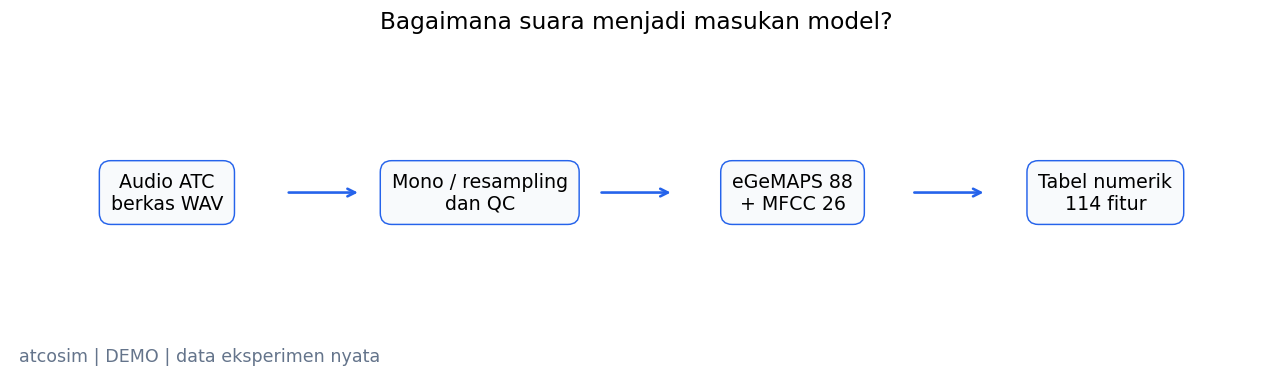

**Yang terlihat:** Alur berakhir pada 114 fitur akustik per ujaran, tanpa kelas fatigue.

**Artinya:** Representasi numerik memungkinkan pengujian model ketika label yang tepat tersedia.

**Perlu diingat:** Diagram menjelaskan proses; tidak menggambarkan model fatigue yang sudah dilatih.

*Sumber: `20261023T105347534495Z_seed42_49cb09` · REAL / CACHED; inference dihitung ulang.*

In [4]:
fig = flow(['Audio ATC\nberkas WAV', 'Mono / resampling\ndan QC', 'eGeMAPS 88\n+ MFCC 26', 'Tabel numerik\n114 fitur'],
           COLORS['audio'], 'Bagaimana suara menjadi masukan model?')
audio_book.show(fig, 'audio_ke_fitur',
                'Alur berakhir pada 114 fitur akustik per ujaran, tanpa kelas fatigue.',
                'Representasi numerik memungkinkan pengujian model ketika label yang tepat tersedia.',
                'Diagram menjelaskan proses; tidak menggambarkan model fatigue yang sudah dilatih.')

## 3. Data mentah dan preprocessing nyata

**Mono** merangkum kanal menjadi satu sinyal. **Resampling** mengubah jumlah sampel per detik agar sesuai extractor; tidak menambahkan informasi baru. Tidak ada denoising tersembunyi atau normalisasi amplitudo yang mengubah statistik suara. Untuk sampel yang sudah mono 16 kHz, perubahan format memang minimal.

In [5]:
import soundfile as sf
from atc_fatigue.audio.features import extract_file, extract_signal, feature_names, resample
sample_audio = audio_manifest.iloc[0]
audio_columns = feature_names(config['audio']['n_mfcc'])
assert len(audio_columns) == 114
if USE_SOURCE_MEDIA:
    raw_signal,source_rate = sf.read(sample_audio.original_path,always_2d=True)
    mono_signal = raw_signal.mean(axis=1)
    prepared_signal = resample(mono_signal,source_rate,config['audio']['sample_rate']).astype(np.float32)
    live_audio_features = extract_file(sample_audio.original_path,config['audio'])
else:
    cached_audio_features = pd.read_parquet(audio_run.path/'features/features.parquet')
    live_audio_features = cached_audio_features[cached_audio_features.sample_id.eq(sample_audio.sample_id)].iloc[0].to_dict()
    source_rate = int(live_audio_features['source_sample_rate'])
    raw_signal,prepared_signal = None,None
source_state = 'FRESH' if USE_SOURCE_MEDIA else 'CACHED'
display(pd.DataFrame([{'Sumber':source_state,'Sample rate sumber (Hz)':source_rate,
    'Kanal sumber':live_audio_features['source_channels'],'Sample rate model (Hz)':config['audio']['sample_rate'],
    'Durasi (detik)':live_audio_features['duration_seconds'],'Quality':live_audio_features['quality']}]))
display(pd.Series(live_audio_features)[audio_columns[:4]+['mfcc_00_mean','mfcc_00_std']].to_frame('Nilai asli — '+source_state))

,Sumber,Sample rate sumber (Hz),Kanal sumber,Sample rate model (Hz),Durasi (detik),Quality
0,FRESH,16000,1,16000,3.299812,ok


,Nilai asli — FRESH
egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,34.928963
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm,0.25542
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile20.0,26.382868
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0,31.587996
mfcc_00_mean,-300.372742
mfcc_00_std,136.381836


### 3.1 Perjalanan satu rekaman ATC asli — pengaturan presentasi lokal

**Pertanyaan:** seperti apa suara yang benar-benar dipakai eksperimen sebelum menjadi 114 angka? **Waveform** adalah amplitudo sinyal terhadap waktu: pola dan level relatif terlihat, tetapi isi frekuensinya belum terpisah. Amplitudo besar tidak otomatis berarti fatigue atau volume absolut yang dapat dibandingkan antarperangkat.

Pada FULL/sesi privat, file contoh dibaca langsung di atas. Pada DEMO publik, metadata dan fitur contoh berasal dari cache asli terverifikasi. Sel berikut menginspeksi dtype decoding, format berkas, kanal, sample rate, dan kualitasnya. **Stereo-to-mono hanya dilakukan bila rekaman memiliki beberapa kanal**; contoh mono tidak dibuat seolah mengalami perubahan stereo. Resampling menyamakan format, tanpa denoising atau penambahan informasi baru.

Grafik suara asli memerlukan opt-in **lokal**: `--private-media` pada runner, atau `ATC_NOTEBOOK_PRIVATE_MEDIA=1` sebelum membuka kernel interaktif. Ini untuk demonstrasi riset lokal sesuai audit penggunaan ATCOSIM; bukan izin redistribusi grafik/rekaman. **Runner selalu menghilangkan output sel bertag `private-media` pada salinan publik**, sambil menyimpan eksekusi asli di `runs/executions/`. Ilustrasi sintetis yang sudah ada tetap dipertahankan untuk pembaca GitHub.

In [6]:
from atc_fatigue.research.data import temporal_audio_representations
PRIVATE_AUDIO = PRIVATE_MEDIA
actual_audio,actual_mfcc = None,None
if USE_SOURCE_MEDIA:
    audio_header = sf.info(sample_audio.original_path)
    actual_audio = temporal_audio_representations(raw_signal,source_rate,config['audio'])
    actual_mfcc = actual_audio['mfcc']
    np.testing.assert_allclose(actual_mfcc.mean(axis=1),[live_audio_features[f'mfcc_{i:02d}_mean'] for i in range(13)],rtol=1e-5,atol=1e-5)
    np.testing.assert_allclose(actual_mfcc.std(axis=1),[live_audio_features[f'mfcc_{i:02d}_std'] for i in range(13)],rtol=1e-5,atol=1e-5)
    temporal_shapes = {'source':'REAL ATCOSIM','source_sample_rate':source_rate,'model_sample_rate':actual_audio['sample_rate'],
        'decoded_dtype':str(raw_signal.dtype),'subtype':audio_header.subtype,
        'waveform_shape':list(actual_audio['prepared_signal'].shape),'stft_shape':list(actual_audio['stft_db'].shape),
        'mel_shape':list(actual_audio['log_mel_db'].shape),'mfcc_shape':list(actual_mfcc.shape),
        'n_fft':actual_audio['n_fft'],'hop_length':actual_audio['hop_length']}
    if RUN_MODE == 'FULL':audio_run.write('features/example_temporal_shapes.json',temporal_shapes)
else:
    temporal_shapes = json.loads((audio_run.path/'features/example_temporal_shapes.json').read_text())
display(pd.DataFrame([temporal_shapes]).T.rename(columns={0:'Representasi nyata — '+source_state}))
print(f"Frame FFT {temporal_shapes['n_fft']} sampel = {temporal_shapes['n_fft']/16000*1000:.0f} ms; hop {temporal_shapes['hop_length']} = {temporal_shapes['hop_length']/16000*1000:.0f} ms.")

,Representasi nyata — FRESH
source,REAL ATCOSIM
source_sample_rate,16000
model_sample_rate,16000
decoded_dtype,float64
subtype,PCM_16
waveform_shape,[52797]
stft_shape,"[1025, 104]"
mel_shape,"[128, 104]"
mfcc_shape,"[13, 104]"
n_fft,2048


Frame FFT 2048 sampel = 128 ms; hop 512 = 32 ms.


In [7]:
if PRIVATE_AUDIO:
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout='constrained')
    axes[0].plot(np.arange(len(raw_signal))/source_rate, raw_signal[:,0], color=COLORS['secondary'], lw=0.7)
    axes[0].set(title=f'Raw waveform: kanal 1 / {raw_signal.shape[1]} kanal, {source_rate} Hz', ylabel='Amplitudo relatif')
    axes[1].plot(np.arange(len(actual_audio['prepared_signal']))/actual_audio['sample_rate'], actual_audio['prepared_signal'], color=COLORS['audio'], lw=0.7)
    axes[1].set(title=f"Sesudah: mono / {actual_audio['sample_rate']} Hz", xlabel='Waktu relatif ujaran (detik)', ylabel='Amplitudo relatif')
    fig.suptitle('ATCOSIM ASLI — raw dan processed waveform dari satu rekaman')
    audio_book.show(fig,'waveform_asli_lokal',f"Durasi sumber {len(raw_signal)/source_rate:.3f} detik; kanal sumber {raw_signal.shape[1]}.",
        'Perbandingan memperlihatkan perubahan format yang benar-benar diperlukan; input mono 16 kHz memang hampir tidak berubah.',
        'Satu contoh tidak mewakili seluruh speaker; grafik sumber ini hanya untuk presentasi lokal.',private=True,origin='FRESH — DATA ASLI LOKAL')
else:
    print('Waveform asli dinonaktifkan untuk output publik; ilustrasi sintetis tetap tersedia di bawah.')

Media sumber hanya tersedia pada salinan eksekusi lokal; output privat dihilangkan dari salinan publik.


### 3.2 Waveform → frekuensi → Mel → MFCC

**Spectrogram** memecah sinyal menjadi jendela pendek, lalu menunjukkan kuatnya komponen frekuensi sepanjang waktu. **STFT** (*Short-Time Fourier Transform*) adalah transformasi yang dipakai: di sini 2.048 sampel per jendela dan hop 512 sampel, sama dengan parameter MFCC baseline librosa. Sumbu Hz menyatakan frekuensi; dB adalah level relatif terhadap maksimum contoh, bukan ukuran tekanan suara terkalibrasi.

**Mel spectrogram** mengelompokkan energi ke 128 pita frekuensi dengan resolusi menyerupai persepsi pendengaran. **MFCC** merangkum bentuk spektrum Mel menjadi koefisien; koefisien bukan pita Hz dan bukan label emosi/fatigue. Seluruh representasi berikut berasal dari **file yang sama**, dengan sample rate dan parameter extractor yang konsisten.

In [8]:
if PRIVATE_AUDIO:
    import librosa.display
    fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
    image = librosa.display.specshow(actual_audio['stft_db'], sr=actual_audio['sample_rate'], hop_length=actual_audio['hop_length'], x_axis='time', y_axis='linear', ax=ax, cmap='magma')
    ax.set(xlabel='Waktu relatif ujaran (detik)',ylabel='Frekuensi (Hz)',title='ATCOSIM ASLI — STFT magnitude setelah preprocessing')
    fig.colorbar(image,ax=ax,label='Magnitude relatif maksimum (dB)')
    audio_book.show(fig,'stft_asli_lokal',f"STFT menghasilkan {actual_audio['stft_db'].shape[0]} bin frekuensi × {actual_audio['stft_db'].shape[1]} frame waktu.",
        'Sumbu frekuensi memisahkan energi yang bercampur pada waveform; warna bukan tingkat fatigue.',
        'Skala dB relatif per contoh; tidak membandingkan loudness absolut antaroperator.',private=True,origin='FRESH — DATA ASLI LOKAL')
else:
    print('STFT rekaman asli tersedia hanya dengan opt-in presentasi lokal.')

Media sumber hanya tersedia pada salinan eksekusi lokal; output privat dihilangkan dari salinan publik.


In [9]:
if PRIVATE_AUDIO:
    fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
    image = librosa.display.specshow(actual_audio['log_mel_db'],sr=actual_audio['sample_rate'],hop_length=actual_audio['hop_length'],x_axis='time',y_axis='mel',ax=ax,cmap='magma')
    ax.set(xlabel='Waktu relatif ujaran (detik)',ylabel='Frekuensi (Hz; skala Mel)',title='ATCOSIM ASLI — 128 pita Mel dari rekaman yang sama')
    fig.colorbar(image,ax=ax,label='Daya relatif maksimum (dB)')
    audio_book.show(fig,'logmel_asli_lokal',f"Log-Mel memiliki {actual_audio['log_mel_db'].shape[0]} pita dan {actual_audio['log_mel_db'].shape[1]} frame waktu.",
        'Pemetaan Mel menekankan struktur spektrum yang menjadi bahan perhitungan MFCC.',
        'Warna bersifat relatif; representasi turunan tetap dapat mengungkap sumber dan tidak dipublikasikan.',private=True,origin='FRESH — DATA ASLI LOKAL')
else:
    print('Log-Mel rekaman asli tersedia hanya pada salinan lokal.')

Media sumber hanya tersedia pada salinan eksekusi lokal; output privat dihilangkan dari salinan publik.


In [10]:
if PRIVATE_AUDIO:
    fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
    image = ax.imshow(actual_mfcc,origin='lower',aspect='auto',cmap='coolwarm',extent=[0,len(actual_audio['prepared_signal'])/actual_audio['sample_rate'],-0.5,12.5])
    ax.set(xlabel='Waktu relatif ujaran (detik)',ylabel='Indeks koefisien MFCC',title='ATCOSIM ASLI — 13 MFCC sebelum diringkas per utterance')
    fig.colorbar(image,ax=ax,label='Nilai koefisien (skala komputasi librosa)')
    audio_book.show(fig,'mfcc_asli_lokal',f"Terdapat 13 koefisien pada {actual_mfcc.shape[1]} frame waktu; rerata/std cocok dengan extractor baseline.",
        'Setiap baris merangkum aspek bentuk spektrum; ringkasan mengubah panjang rekaman berbeda menjadi vektor tetap.',
        'Mean/std membuang urutan perubahan; distribusi koefisien bukan bukti kondisi fatigue.',private=True,origin='FRESH — DATA ASLI LOKAL')
else:
    print('Heatmap MFCC rekaman asli tidak disimpan pada notebook publik.')

Media sumber hanya tersedia pada salinan eksekusi lokal; output privat dihilangkan dari salinan publik.


### 3.3 Mengapa akhirnya ada 114 fitur?

Konfigurasi **eGeMAPSv02 Functionals** secara definisi mengeluarkan 88 ringkasan akustik; angka ini berasal dari spesifikasi feature set, bukan hasil pemilihan jumlah fitur berdasarkan skor. MFCC di baseline memakai 13 koefisien, masing-masing diringkas dengan mean (rerata) dan std (simpangan baku): **13 × 2 = 26**. Keduanya menghasilkan **88 + 26 = 114** kolom numerik per utterance.

Contoh: mean MFCC menggambarkan bentuk spektrum rata-rata, sementara std menggambarkan variasinya selama ujaran. Fitur pitch merangkum pola nada dengan unit yang perlu dibaca per kolom. Ringkasan ini tidak mempertahankan semua urutan waktu, dapat berubah karena mikrofon/bahasa/noise, dan tidak spesifik fatigue. Tanpa label fatigue independen, ekstraksi yang berhasil belum berarti model mendeteksi kelelahan.

In [11]:
display(pd.DataFrame([
    {'Representasi':'Waveform','Shape':str(temporal_shapes['waveform_shape']),'Makna':'Amplitudo terhadap waktu'},
    {'Representasi':'STFT','Shape':str(temporal_shapes['stft_shape']),'Makna':'Bin frekuensi × frame waktu'},
    {'Representasi':'Log-Mel','Shape':str(temporal_shapes['mel_shape']),'Makna':'128 pita perseptual × frame waktu'},
    {'Representasi':'MFCC temporal','Shape':str(temporal_shapes['mfcc_shape']),'Makna':'13 koefisien × frame waktu'},
    {'Representasi':'eGeMAPSv02 Functionals','Shape':'[1,88]','Makna':'Ringkasan akustik dengan unit berbeda'},
    {'Representasi':'Model row','Shape':str((1,len(audio_columns))),'Makna':'88 eGeMAPS + 13 MFCC mean + 13 MFCC std'}]))
print('Sumber bentuk temporal:',source_state,'; MFCC canonical memakai default librosa, bukan gambar log-Mel yang dinormalisasi untuk tampilan.')

,Representasi,Shape,Makna
0,Waveform,[52797],Amplitudo terhadap waktu
1,STFT,"[1025, 104]",Bin frekuensi × frame waktu
2,Log-Mel,"[128, 104]",128 pita perseptual × frame waktu
3,MFCC temporal,"[13, 104]",13 koefisien × frame waktu
4,eGeMAPSv02 Functionals,"[1,88]",Ringkasan akustik dengan unit berbeda
5,Model row,"(1, 114)",88 eGeMAPS + 13 MFCC mean + 13 MFCC std


Sumber bentuk temporal: FRESH ; MFCC canonical memakai default librosa, bukan gambar log-Mel yang dinormalisasi untuk tampilan.


### Membaca bentuk sinyal tanpa membagikan suara peserta

Ilustrasi deterministik berikut terdiri dari tiga gelombang harmonik dan perubahan amplitudo; ini **bukan suara ATC**. Sumbu waktu tetap detik. Contoh memperlihatkan perubahan representasi stereo 32 kHz menjadi mono 16 kHz; tabel sebelumnya menunjukkan preprocessing pada file asli.

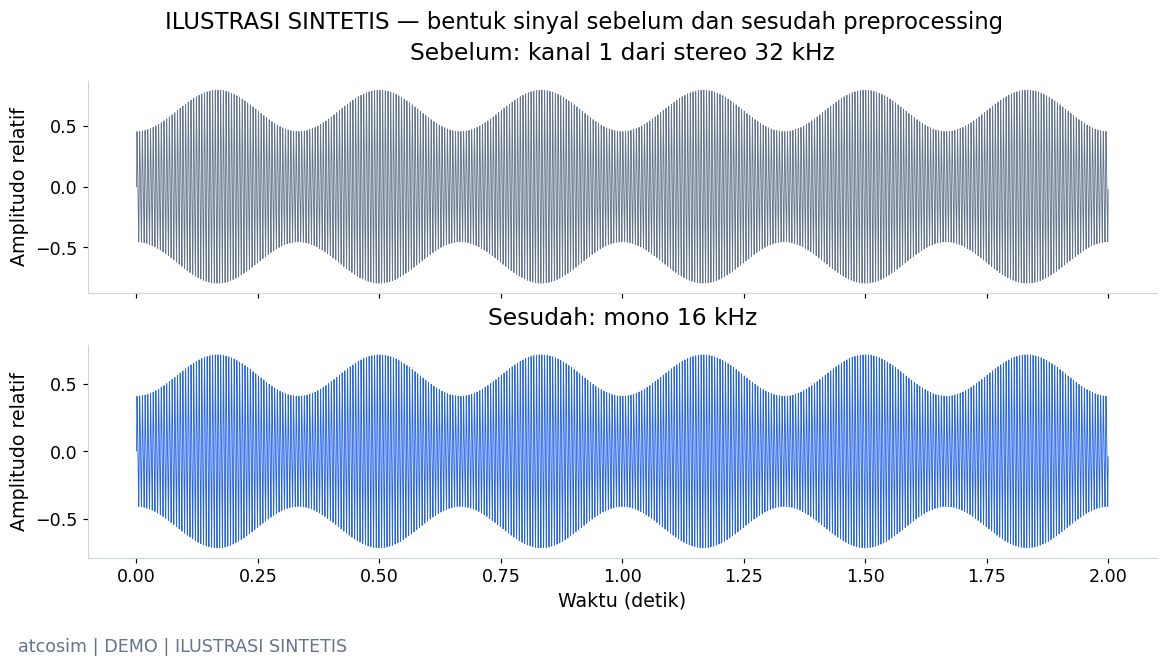

**Yang terlihat:** Sinyal dua detik mempertahankan durasi setelah jumlah sampel per detik diubah.

**Artinya:** Resampling menyamakan format masukan extractor, bukan membuat label.

**Perlu diingat:** Sinyal ini buatan dan tidak masuk eksperimen atau skor.

*Sumber: `20261023T105347534495Z_seed42_49cb09` · REAL / CACHED; inference dihitung ulang.*

In [12]:
illustration_rate = 32000
illustration_time = np.arange(illustration_rate * 2) / illustration_rate
envelope = 0.4 + 0.3 * np.sin(2*np.pi*1.5*illustration_time)**2
synthetic_mono = envelope * (np.sin(2*np.pi*180*illustration_time) + 0.3*np.sin(2*np.pi*360*illustration_time))
synthetic_stereo = np.column_stack([synthetic_mono, synthetic_mono*0.8])
synthetic_prepared = resample(synthetic_stereo.mean(axis=1), illustration_rate, 16000)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.8), layout='constrained', sharex=True)
axes[0].plot(illustration_time, synthetic_stereo[:, 0], color=COLORS['secondary'], lw=0.6)
axes[1].plot(np.arange(len(synthetic_prepared))/16000, synthetic_prepared, color=COLORS['audio'], lw=0.6)
for ax, label in zip(axes, ['Sebelum: kanal 1 dari stereo 32 kHz', 'Sesudah: mono 16 kHz']):
    ax.set(ylabel='Amplitudo relatif', title=label)
axes[1].set_xlabel('Waktu (detik)')
fig.suptitle('ILUSTRASI SINTETIS — bentuk sinyal sebelum dan sesudah preprocessing')
audio_book.show(fig, 'waveform_sintetis',
                'Sinyal dua detik mempertahankan durasi setelah jumlah sampel per detik diubah.',
                'Resampling menyamakan format masukan extractor, bukan membuat label.',
                'Sinyal ini buatan dan tidak masuk eksperimen atau skor.', synthetic=True)

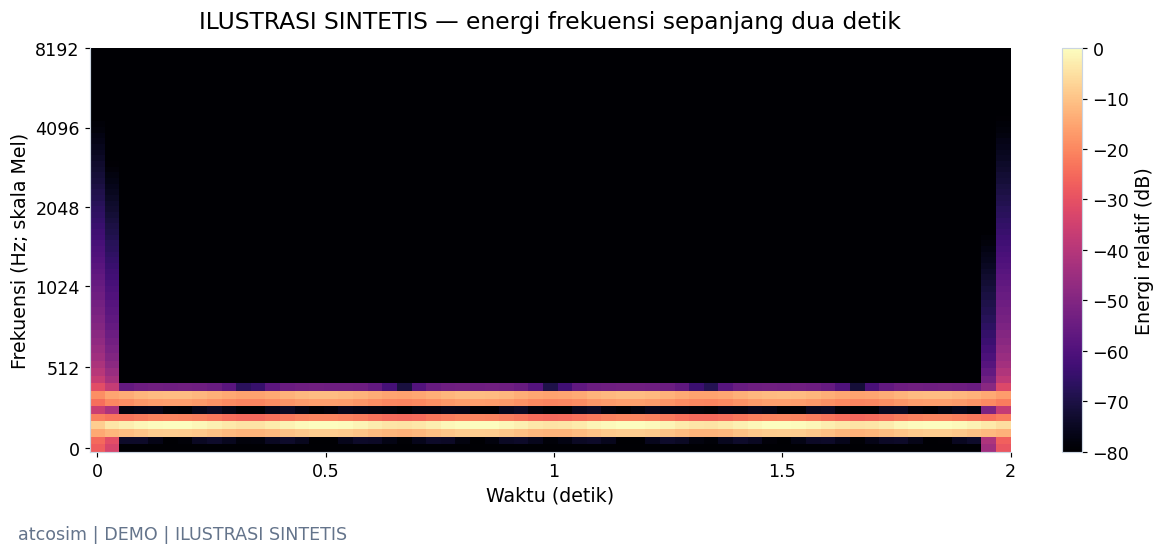

**Yang terlihat:** Energi terkonsentrasi di frekuensi harmonik yang dipakai membentuk sinyal buatan.

**Artinya:** Spektrogram memisahkan informasi waktu dan frekuensi yang tidak terlihat pada satu angka RMS.

**Perlu diingat:** Mel menekankan resolusi frekuensi menurut persepsi pendengaran; bukan indikator fatigue.

*Sumber: `20261023T105347534495Z_seed42_49cb09` · REAL / CACHED; inference dihitung ulang.*

In [13]:
import librosa
import librosa.display
mel_power = librosa.feature.melspectrogram(y=synthetic_prepared, sr=16000, n_mels=64)
log_mel = librosa.power_to_db(mel_power, ref=np.max)
fig, ax = plt.subplots(layout='constrained')
image = librosa.display.specshow(log_mel, sr=16000, x_axis='time', y_axis='mel', ax=ax, cmap='magma')
ax.set(xlabel='Waktu (detik)', ylabel='Frekuensi (Hz; skala Mel)',
       title='ILUSTRASI SINTETIS — energi frekuensi sepanjang dua detik')
fig.colorbar(image, ax=ax, label='Energi relatif (dB)')
audio_book.show(fig, 'logmel_sintetis',
                'Energi terkonsentrasi di frekuensi harmonik yang dipakai membentuk sinyal buatan.',
                'Spektrogram memisahkan informasi waktu dan frekuensi yang tidak terlihat pada satu angka RMS.',
                'Mel menekankan resolusi frekuensi menurut persepsi pendengaran; bukan indikator fatigue.', synthetic=True)

## 4. Feature engineering: dari spektrum ke tabel

**eGeMAPS** adalah paket 88 ringkasan fitur akustik, termasuk nada, energi, spektrum, dan kualitas suara. **MFCC** (*Mel-frequency cepstral coefficients*) merangkum bentuk spektrum; 13 koefisien dihitung sepanjang waktu, lalu masing-masing diringkas dengan rerata dan simpangan baku: **13 × 2 = 26**.

Satu nilai fitur belum memiliki arti klinis. Unit antarfitur berbeda: pitch semitone bukan Hz, loudness bukan RMS, dan nilai MFCC bersifat koefisien. Tabel contoh asli di atas sengaja hanya menampilkan beberapa kolom.

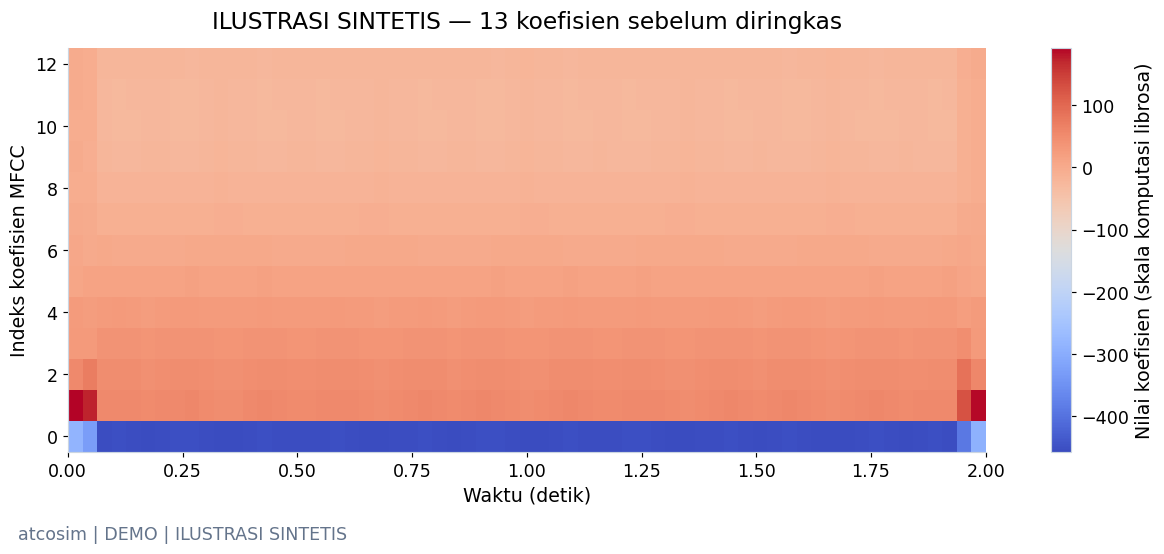

**Yang terlihat:** Setiap baris mengikuti satu koefisien; tabel model merangkum rerata dan variasinya.

**Artinya:** Ringkasan mengubah sinyal berdurasi berbeda menjadi vektor dengan panjang tetap.

**Perlu diingat:** Matriks ini sintetis; 114 fitur eksperimen dihitung dari audio ATCOSIM asli.

*Sumber: `20261023T105347534495Z_seed42_49cb09` · REAL / CACHED; inference dihitung ulang.*

In [14]:
synthetic_mfcc = librosa.feature.mfcc(y=synthetic_prepared, sr=16000, n_mfcc=13)
fig, ax = plt.subplots(layout='constrained')
image = ax.imshow(synthetic_mfcc, aspect='auto', origin='lower', cmap='coolwarm',
                  extent=[0, 2, -0.5, 12.5])
ax.set(xlabel='Waktu (detik)', ylabel='Indeks koefisien MFCC',
       title='ILUSTRASI SINTETIS — 13 koefisien sebelum diringkas')
fig.colorbar(image, ax=ax, label='Nilai koefisien (skala komputasi librosa)')
audio_book.show(fig, 'mfcc_sintetis',
                'Setiap baris mengikuti satu koefisien; tabel model merangkum rerata dan variasinya.',
                'Ringkasan mengubah sinyal berdurasi berbeda menjadi vektor dengan panjang tetap.',
                'Matriks ini sintetis; 114 fitur eksperimen dihitung dari audio ATCOSIM asli.', synthetic=True)

## 5. Ekstraksi seluruh subset dan quality control

Pada **FULL**, loop berikut benar-benar membaca semua file dan mengekstrak fiturnya. Pada **DEMO**, tabel seluruh subset diambil dari run tersimpan yang telah diverifikasi, tanpa membuka raw audio; sesi privat dapat menghitung contoh asli langsung. Sampel hening/terlalu pendek menghasilkan flag dan nilai hilang, bukan fitur suara nol yang dianggap valid.

In [15]:
if RUN_MODE == 'FULL':
    extraction_started = time.perf_counter()
    audio_rows = []
    for row in audio_manifest.to_dict('records'):
        audio_rows.append({**row, **extract_file(row['original_path'], config['audio'])})
    audio_features = pd.DataFrame(audio_rows)
    audio_run.features(audio_features, audio_columns, 'audio-egemapsv02-mfcc13-v1')
    audio_run.log('extract_all_audio', {'rows': len(audio_features), 'seconds': time.perf_counter()-extraction_started})
else:
    audio_features = pd.read_parquet(audio_run.path / 'features/features.parquet')
np.testing.assert_allclose(audio_features.loc[audio_features.sample_id.eq(sample_audio.sample_id), audio_columns].iloc[0].to_numpy(float),
                           np.array([live_audio_features[c] for c in audio_columns]), equal_nan=True, rtol=1e-5)
audio_qc = {'rows': len(audio_features), 'subjects': int(audio_features.subject_id.nunique()),
            'sessions': int(audio_features.session_id.nunique()),
            'duration_seconds': float(audio_features.duration_seconds.sum()),
            'feature_missing_fraction': float(audio_features[audio_columns].isna().mean().mean()),
            'quality_counts': audio_features.quality.value_counts().to_dict(),
            'evaluation_rows': len(audio_features)}
display(audio_features[['duration_seconds', 'source_sample_rate', 'source_channels', 'quality']].head())
display(pd.DataFrame([audio_qc]).drop(columns='quality_counts'))

,duration_seconds,source_sample_rate,source_channels,quality
0,3.299812,16000,1,ok
1,4.660000,16000,1,ok
2,4.229813,16000,1,ok
3,2.640000,16000,1,ok
4,3.910000,16000,1,ok


,rows,subjects,sessions,duration_seconds,feature_missing_fraction,evaluation_rows
0,100,1,1,425.614688,0.0,100


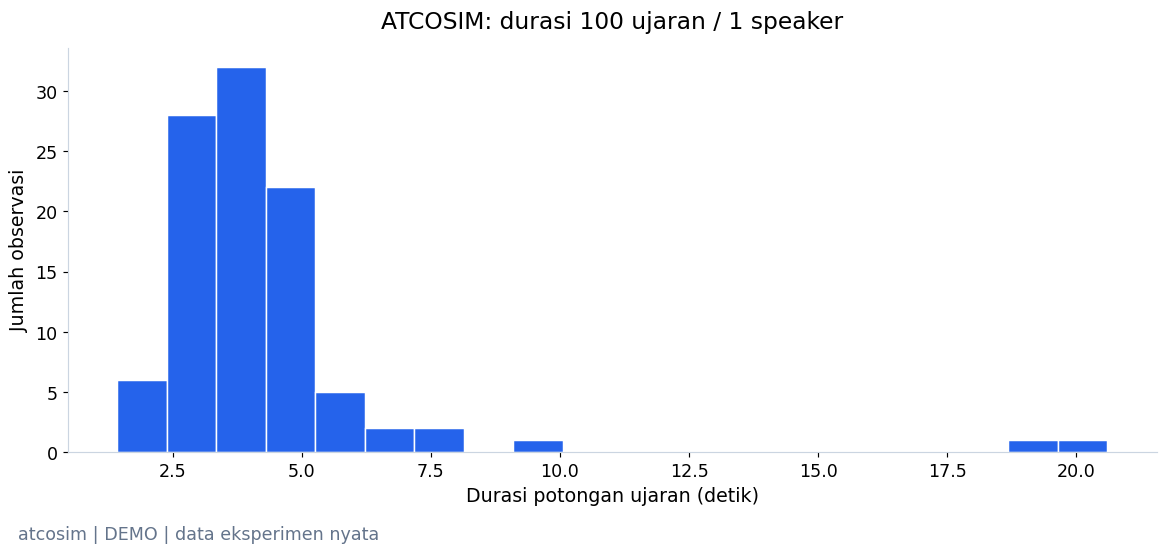

**Yang terlihat:** Total audio 425.61 detik; median ujaran 3.92 detik.

**Artinya:** Durasi bervariasi, sehingga ringkasan fitur berdimensi tetap membantu menyusun tabel.

**Perlu diingat:** Ini durasi potongan rekaman, bukan waktu speech bersih hasil VAD atau sesi kontinu.

*Sumber: `20261023T105347534495Z_seed42_49cb09` · REAL / CACHED; inference dihitung ulang.*

In [16]:
fig = histogram(audio_features.duration_seconds, 'Durasi potongan ujaran (detik)',
                f'ATCOSIM: durasi {len(audio_features)} ujaran / {audio_features.subject_id.nunique()} speaker', COLORS['audio'])
audio_book.show(fig, 'distribusi_durasi',
                f'Total audio {audio_qc["duration_seconds"]:.2f} detik; median ujaran {audio_features.duration_seconds.median():.2f} detik.',
                'Durasi bervariasi, sehingga ringkasan fitur berdimensi tetap membantu menyusun tabel.',
                'Ini durasi potongan rekaman, bukan waktu speech bersih hasil VAD atau sesi kontinu.')

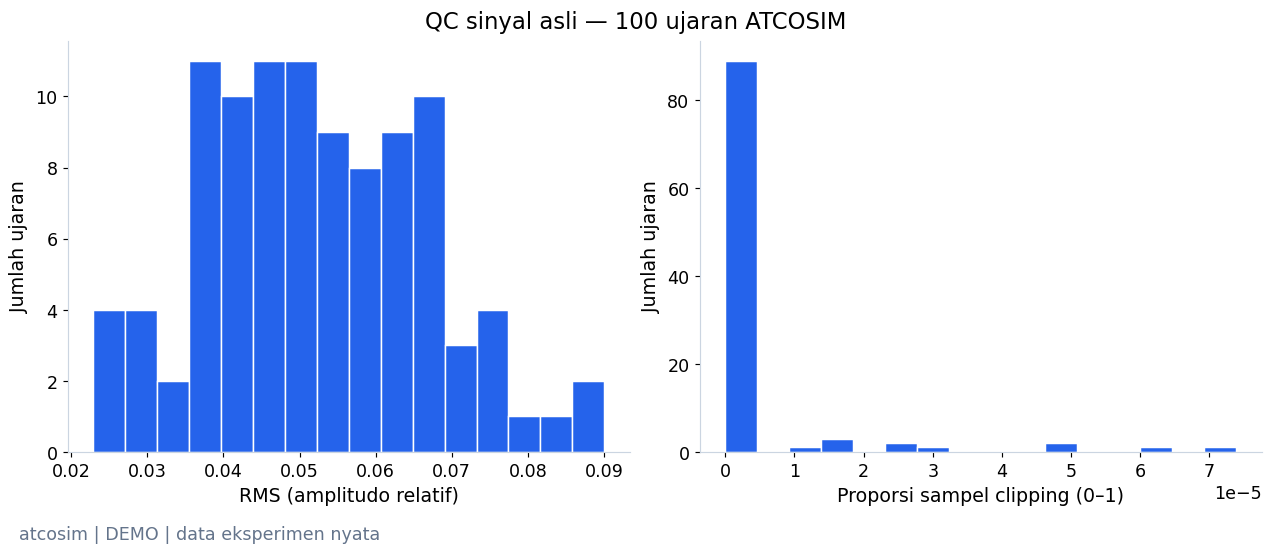

**Yang terlihat:** RMS median 0.051524; clipping maksimum 0.000074.

**Artinya:** Pemeriksaan ini mendeteksi persoalan level sinyal sebelum fitur dipakai model.

**Perlu diingat:** RMS dan clipping bukan estimasi SNR, VAD, atau kondisi fatigue.

*Sumber: `20261023T105347534495Z_seed42_49cb09` · REAL / CACHED; inference dihitung ulang.*

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for ax, column, label in zip(axes, ['rms', 'clipping_fraction'], ['RMS (amplitudo relatif)', 'Proporsi sampel clipping (0–1)']):
    ax.hist(audio_features[column], bins=16, color=COLORS['audio'], edgecolor='white')
    ax.set(xlabel=label, ylabel='Jumlah ujaran')
    ax.ticklabel_format(axis='x', style='sci', scilimits=(-3, 3))
fig.suptitle(f'QC sinyal asli — {len(audio_features)} ujaran ATCOSIM')
audio_book.show(fig, 'rms_dan_clipping',
                f'RMS median {audio_features.rms.median():.6f}; clipping maksimum {audio_features.clipping_fraction.max():.6f}.',
                'Pemeriksaan ini mendeteksi persoalan level sinyal sebelum fitur dipakai model.',
                'RMS dan clipping bukan estimasi SNR, VAD, atau kondisi fatigue.')

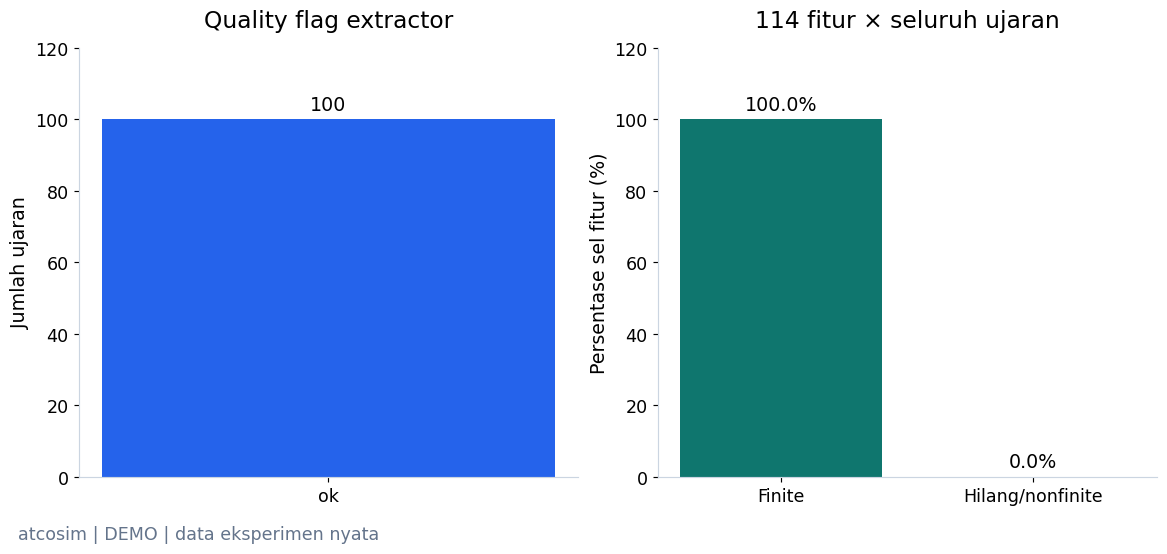

**Yang terlihat:** 100 ujaran tersedia; 100.0% sel fitur finite.

**Artinya:** Pipeline dapat membentuk tabel tanpa mengarang pengukuran pada sampel tidak valid.

**Perlu diingat:** Quality ok adalah kelayakan teknis ekstraksi, bukan validasi biomarker atau generalisasi.

*Sumber: `20261023T105347534495Z_seed42_49cb09` · REAL / CACHED; inference dihitung ulang.*

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
counts = audio_features.quality.value_counts()
bars = axes[0].bar(counts.index, counts.values, color=COLORS['audio'])
axes[0].bar_label(bars, padding=4)
axes[0].set(ylabel='Jumlah ujaran', title='Quality flag extractor', ylim=(0, counts.max()*1.2))
finite_percent = 100 * np.isfinite(audio_features[audio_columns].to_numpy(float)).mean()
bars = axes[1].bar(['Finite', 'Hilang/nonfinite'], [finite_percent, 100-finite_percent],
                   color=[COLORS['fusion'], COLORS['error']])
axes[1].bar_label(bars, fmt='%.1f%%', padding=4)
axes[1].set(ylabel='Persentase sel fitur (%)', title='114 fitur × seluruh ujaran', ylim=(0, 120))
audio_book.show(fig, 'kualitas_dan_missingness',
                f'{int(audio_features.audio_available.sum())} ujaran tersedia; {finite_percent:.1f}% sel fitur finite.',
                'Pipeline dapat membentuk tabel tanpa mengarang pengukuran pada sampel tidak valid.',
                'Quality ok adalah kelayakan teknis ekstraksi, bukan validasi biomarker atau generalisasi.')

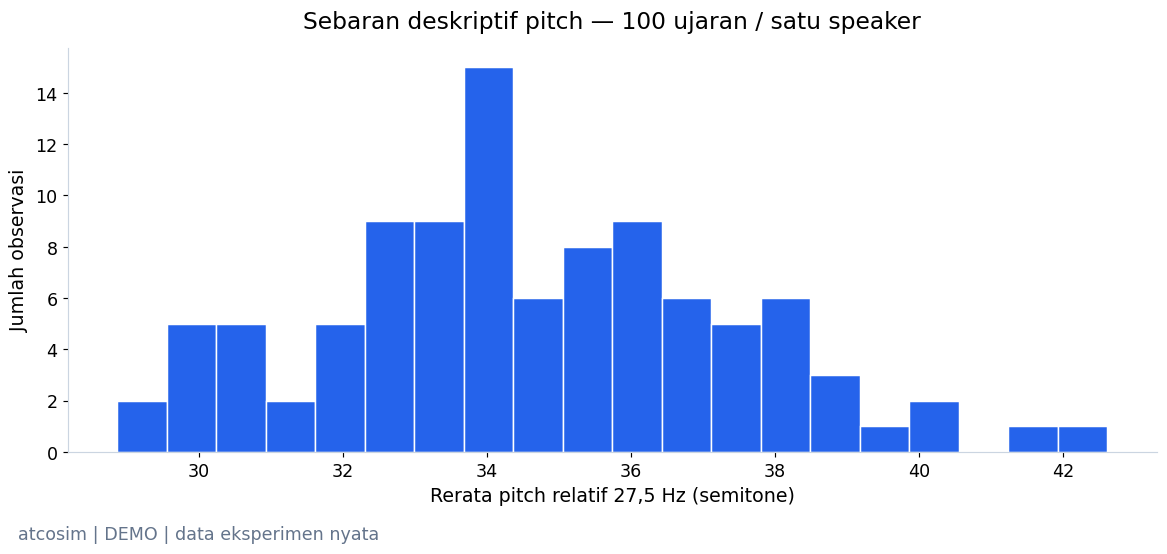

**Yang terlihat:** Median fitur pitch pada subset 34.30 semitone.

**Artinya:** Satu fitur memiliki variasi antarujaran meskipun berasal dari speaker yang sama.

**Perlu diingat:** Tidak ada kelompok fatigue/non-fatigue untuk menguji apakah variasi ini berkaitan dengan kelelahan.

*Sumber: `20261023T105347534495Z_seed42_49cb09` · REAL / CACHED; inference dihitung ulang.*

In [19]:
pitch_column = next(c for c in audio_columns if 'F0semitoneFrom27.5Hz_sma3nz_amean' in c)
fig = histogram(audio_features[pitch_column].to_numpy(float), 'Rerata pitch relatif 27,5 Hz (semitone)',
                f'Sebaran deskriptif pitch — {len(audio_features)} ujaran / satu speaker', COLORS['audio'])
audio_book.show(fig, 'distribusi_pitch',
                f'Median fitur pitch pada subset {audio_features[pitch_column].median():.2f} semitone.',
                'Satu fitur memiliki variasi antarujaran meskipun berasal dari speaker yang sama.',
                'Tidak ada kelompok fatigue/non-fatigue untuk menguji apakah variasi ini berkaitan dengan kelelahan.')

## 6. Temuan, keterbatasan, dan langkah berikutnya

Pipeline menghasilkan representasi akustik dan QC yang dapat diperiksa. Subset first-100 dari satu speaker/sesi belum menguji variasi aksen, operator, mikrofon, atau radio terkompresi. Tidak ada timeline pilot yang sah untuk menghitung latency respons, dan tidak ada label fatigue untuk melatih classifier.

Kandidat berikutnya adalah IEEE ATC Radiotelephony Fatigue Corpus, DOI `10.21227/70sz-mj23`. **Menurut pembaruan pengguna pada spesifikasi v3, permintaan akses sudah dikirim; akses/data belum tersedia.** Notebook tidak mencoba mengunduh atau melewati login. Setelah akses sah, label, speaker, channel, duplikasi dan split perlu diaudit terlebih dahulu.

## 7. Provenance dan reproduksi

FULL menyimpan manifest sumber, konfigurasi, versi environment, schema, Parquet, QC, log dan grafik. File model/prediksi tidak berlaku karena tidak ada label. Grafik ilustrasi sintetis tidak digunakan sebagai data eksperimen.

In [20]:
audio_book.finish()
if RUN_MODE == 'FULL':
    audio_metrics = metrics_base(audio_run, {}, {}, {}, baseline=None)
    audio_run.complete(audio_metrics, audio_qc, warning_records)
display(pd.DataFrame([{'Run ID': audio_run.manifest['run_id'], 'Mode': RUN_MODE,
                       'Ujaran': len(audio_features), 'Fitur': len(audio_columns),
                       'Metrik supervised': 'N/A — no_fatigue_labels',
                       'Artifact': str(audio_run.path.relative_to(ROOT))}]))

,Run ID,Mode,Ujaran,Fitur,Metrik supervised,Artifact
0,20261023T105347534495Z_seed42_49cb09,DEMO,100,114,N/A — no_fatigue_labels,runs/atcosim_audio/20261023T105347534495Z_seed...


## 7. Audit kandidat fatigue: apa sebenarnya label Predi-COVID?

**Pertanyaan:** apakah kita dapat melatih model suara dengan target fatigue yang benar-benar tercatat?
ATCOSIM tidak menyediakan label tersebut. Predi-COVID menyediakan rekaman peserta dengan COVID-19 terkonfirmasi,
beserta laporan keadaan hari itu. Ini membuka supervised benchmark **fatigue klinis**, dengan domain gap besar terhadap ATC.

Menurut [paper peneliti](https://bmjopen.bmj.com/content/12/11/e062463), jawaban *I feel well* menjadi kelas 0;
*I am fatigued* **dan** *I don't feel well* menjadi kelas 1. Jadi kelas 1 mencampur kelelahan dengan rasa tidak sehat;
bukan diagnosis objektif, skala occupational fatigue, atau label yang dinilai per segmen suara.
[Zenodo 5937844](https://zenodo.org/records/5937844) menyediakan WAV dan metadata terbuka CC BY 4.0.
Kode penulis tidak disalin; notebook ini memakai extractor 114 fitur yang sama dengan ATCOSIM.

| Audit | Keputusan sebelum melihat performa |
| :--- | :--- |
| Arsip sumber | 3.544 WAV / 296 peserta; membaca teks (tipe 1) dan vokal (tipe 2), total sekitar 4,38 GiB |
| Subset berizin | Seed 42 memilih 120 peserta; maksimal dua rekaman membaca teks paling awal per peserta: 207 WAV, sekitar 338 MiB |
| Pemilihan | Tidak memakai skor model atau mencari kelas paling mudah; bukan sampel representatif populasi klinis |
| Identitas berulang | Semua rekaman/hari dari satu peserta tetap dalam satu split; hash duplikat diperiksa lintas split |
| Label | Binary publisher; keadaan klinis sehari, bukan fatigue ATC |
| Confound | Penyakit, demografi, perangkat/format asli, bahasa, tanggal dan protokol membaca |
| Bahasa | Sumber studi multibahasa; bahasa per rekaman tidak tersedia pada nama file, sehingga belum dapat dikontrol |
| Publikasi | Hanya ringkasan agregat; WAV, metadata peserta, model dan cache fitur tetap lokal |

**Input → output:** manifest lokal dengan checksum → QC audio → fitur 114 dimensi → split peserta → model tetap → prediksi holdout.
Tidak ada unduhan otomatis ketika Run All. Jika manifest belum tersedia, bagian ini menjelaskan kebutuhan akses dan tidak membuat skor pengganti.

In [21]:
PREDI_AVAILABLE = Path(config['additional_datasets']['predi_manifest']).exists()
if PREDI_AVAILABLE:
    predi_manifest = local_manifest(config['additional_datasets']['predi_manifest'], target='clinical_fatigue_binary', verify_media=USE_SOURCE_MEDIA)
    predi_rights = {'source':'https://zenodo.org/records/5937844', 'variant':'seed42;120 participants;task1;max2 earliest;207 recordings',
                    'rights':'CC BY 4.0; LIHVOICE; clinical data; aggregate-only public presentation'}
    predi_limits = ['clinical fatigue/unwell self-report is not occupational ATC fatigue',
                    'COVID illness, language, device and demographics may confound acoustic associations',
                    'repeated same-subject measurements; small fixed subject-independent subset',
                    'recording-level scores; clips within subjects are dependent; no clip-level confidence interval']
    if RUN_MODE == 'FULL':
        predi_run = Run.create('predi_covid_fatigue','01_audio_analysis.ipynb',config,predi_manifest,
                               'audio-egemapsv02-mfcc13-v1',predi_rights,predi_limits)
    else:
        predi_run,predi_metrics = cached_run('predi_covid_fatigue',config)
    predi_book = FigureBook(predi_run,RUN_MODE,config)
    run_card(predi_run,RUN_MODE,'Target: clinical_fatigue_binary; bukan fatigue ATC')
else:
    display(Markdown('**BLOCKED lokal:** manifest Predi-COVID belum tersedia. Persiapkan subset berizin; tidak ada training atau skor fiktif.'))

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; inference checkpoint dihitung ulang, tanpa training baru** |
| Run ID sumber | `20261023T105402224766Z_seed42_880107` |
| Status eksperimen sumber | completed |
| Dataset / target | predi_covid / clinical_fatigue_binary |
| Sampel / subjek | 207 / 120 |
| Unit evaluasi | recording; held-out participant |
| Hasil utama | Target: clinical_fatigue_binary; bukan fatigue ATC |

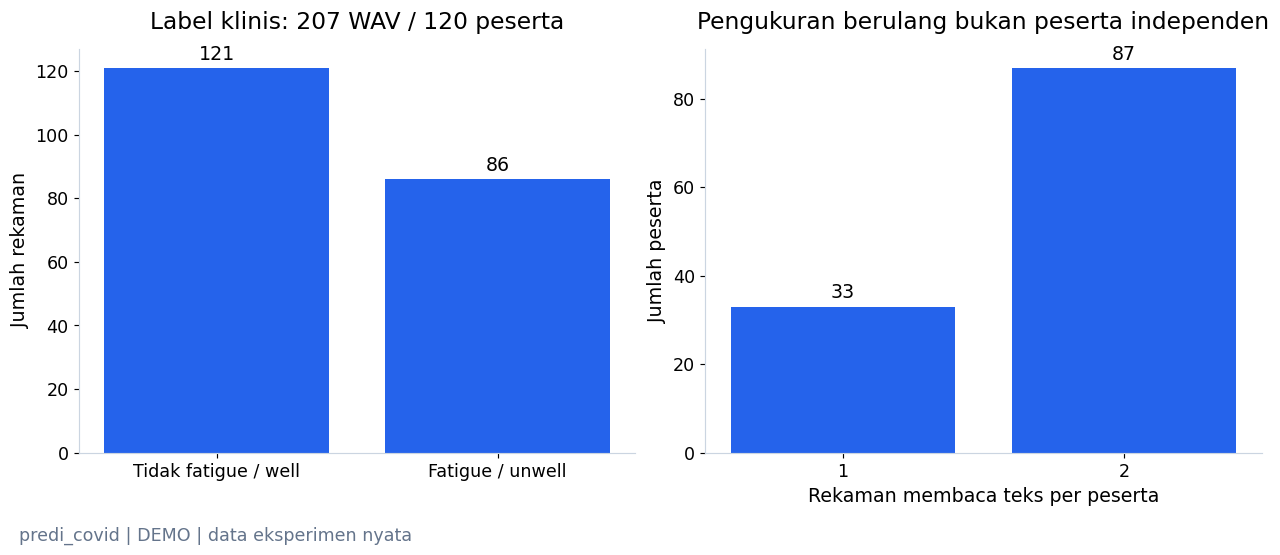

**Yang terlihat:** Kelas 0 berisi 121 rekaman, kelas 1 berisi 86; subset maksimal dua rekaman per peserta.

**Artinya:** Ketidakseimbangan kelas memerlukan baseline mayoritas, Macro F1, balanced accuracy dan recall tiap kelas.

**Perlu diingat:** Label unwell mencakup gejala selain fatigue; dua rekaman dari orang sama tidak setara dua orang.

*Sumber: `20261023T105402224766Z_seed42_880107` · FRESH — manifest sumber terverifikasi.*

Label klinis                 0   1
sex_metadata source_format        
M            3gp            29  16
             m4a            37  15
W            3gp            13  20
             m4a            42  35

In [22]:
if PREDI_AVAILABLE:
    fig, axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
    counts = predi_manifest.target_value.value_counts().reindex([0,1],fill_value=0)
    bars = axes[0].bar(['Tidak fatigue / well','Fatigue / unwell'],counts,color=COLORS['audio'])
    axes[0].bar_label(bars,padding=3)
    axes[0].set(ylabel='Jumlah rekaman',title=f'Label klinis: {len(predi_manifest)} WAV / {predi_manifest.subject_id.nunique()} peserta')
    repeats = predi_manifest.groupby('subject_id').size().value_counts().sort_index()
    bars = axes[1].bar(repeats.index.astype(str),repeats.values,color=COLORS['audio'])
    axes[1].bar_label(bars,padding=3)
    axes[1].set(xlabel='Rekaman membaca teks per peserta',ylabel='Jumlah peserta',title='Pengukuran berulang bukan peserta independen')
    predi_book.show(fig,'predi_label_dan_pengulangan',
                    f'Kelas 0 berisi {counts[0]} rekaman, kelas 1 berisi {counts[1]}; subset maksimal dua rekaman per peserta.',
                    'Ketidakseimbangan kelas memerlukan baseline mayoritas, Macro F1, balanced accuracy dan recall tiap kelas.',
                    'Label unwell mencakup gejala selain fatigue; dua rekaman dari orang sama tidak setara dua orang.',origin='FRESH — manifest sumber terverifikasi')
    display(predi_manifest.groupby(['sex_metadata','source_format','target_value']).size().unstack(fill_value=0).rename_axis(columns='Label klinis'))

### 7.1 QC dan split peserta sebelum training

**Mengapa tahap ini diperlukan?** File yang berhasil diunduh belum tentu memuat sinyal yang layak.
Checksum SHA-256 dan MD5 penerbit diverifikasi saat persiapan; extractor memeriksa durasi, RMS (kuat sinyal rata-rata),
clipping (amplitudo mencapai batas digital), sample rate, kanal, serta nilai fitur yang hilang.
Semua rekaman diperiksa. Tidak ada penghapusan berdasarkan skor model; jika fitur tidak valid, eksekusi berhenti untuk audit.

Split `GroupShuffleSplit` memakai seed 42: sekitar 20% peserta test, lalu 20% dari sisanya validation.
Batas subjek diperiksa sebelum fitting. Validation ditampilkan untuk transparansi dan **tidak** dipakai mencari parameter terbaik.
Format 3GP/M4A pada metadata adalah format perangkat **sebelum** konversi penerbit ke WAV; bukan format berkas yang kita decode sekarang.

,Rekaman,Peserta,Fatigue,Durasi_detik
split,,,,
test,42,24,18,1196.308955
train,129,76,46,3653.019825
validation,36,20,22,1015.339957


,Rekaman,RMS_min,Clipping_maks,Sample_rate_min
quality,,,,
ok,207,0.024156,0.0,8000


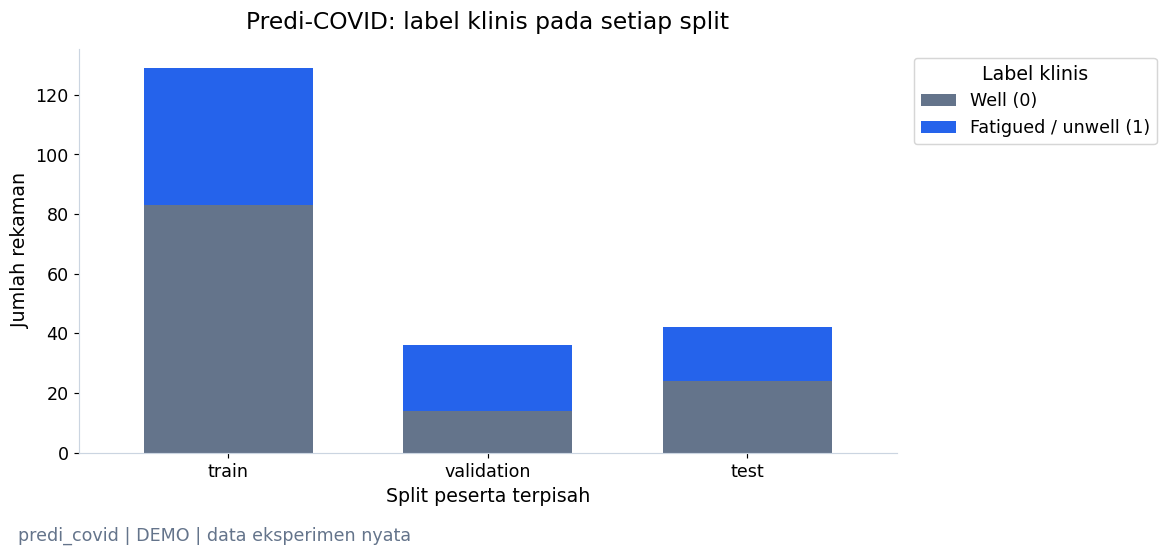

**Yang terlihat:** Seluruh hari dan rekaman seorang peserta berada pada satu bagian data; overlap subjek dan checksum lintas split = 0.

**Artinya:** Model diuji pada peserta yang tidak dipakai fitting, sehingga tidak cukup menghafal identitas suara training.

**Perlu diingat:** Split independen tidak menghapus confound klinis atau memastikan populasi test mewakili operator ATC.

*Sumber: `20261023T105402224766Z_seed42_880107` · REAL / CACHED; inference dihitung ulang.*

In [23]:
if PREDI_AVAILABLE:
    from atc_fatigue.models.baselines import subject_split, classification_metrics
    if RUN_MODE == 'FULL':
        predi_rows = [{**row,**extract_file(row['original_path'],config['audio'])}
                      for row in predi_manifest.to_dict('records')]
        predi_data = subject_split(pd.DataFrame(predi_rows),config['seed'])
        if not np.isfinite(predi_data[audio_columns].to_numpy(float)).all() or not predi_data.quality.eq('ok').all():
            raise ValueError('Predi-COVID QC requires explicit review; no silent removal or substitution')
        predi_run.features(predi_data,audio_columns,'audio-egemapsv02-mfcc13-v1')
        predi_data[['sample_id','subject_id','session_id','source_checksum','target_value','split']].to_csv(
            predi_run.file('split_manifest.csv'),index=False)
    else:
        predi_data = pd.read_parquet(predi_run.path/'features/features.parquet')
    assert predi_data.groupby('subject_id').split.nunique().max()==1
    assert predi_data.groupby('source_checksum').split.nunique().max()==1
    predi_sizes = predi_data.groupby('split').size().to_dict()
    display(predi_data.groupby('split').agg(Rekaman=('sample_id','size'),Peserta=('subject_id','nunique'),
                                           Fatigue=('target_value','sum'),Durasi_detik=('duration_seconds','sum')))
    display(predi_data.groupby('quality').agg(Rekaman=('sample_id','size'),RMS_min=('rms','min'),
                                              Clipping_maks=('clipping_fraction','max'),Sample_rate_min=('source_sample_rate','min')))
    split_labels = pd.crosstab(predi_data.split,predi_data.target_value).reindex(['train','validation','test'])
    fig,ax = plt.subplots(layout='constrained')
    split_labels.rename(columns={0:'Well (0)',1:'Fatigued / unwell (1)'}).plot.bar(
        stacked=True,ax=ax,rot=0,color=[COLORS['secondary'],COLORS['audio']],width=.65)
    ax.set(xlabel='Split peserta terpisah',ylabel='Jumlah rekaman',title='Predi-COVID: label klinis pada setiap split')
    ax.legend(title='Label klinis',loc='upper left',bbox_to_anchor=(1.01,1))
    predi_book.show(fig,'predi_split',
                    'Seluruh hari dan rekaman seorang peserta berada pada satu bagian data; overlap subjek dan checksum lintas split = 0.',
                    'Model diuji pada peserta yang tidak dipakai fitting, sehingga tidak cukup menghafal identitas suara training.',
                    'Split independen tidak menghapus confound klinis atau memastikan populasi test mewakili operator ATC.')

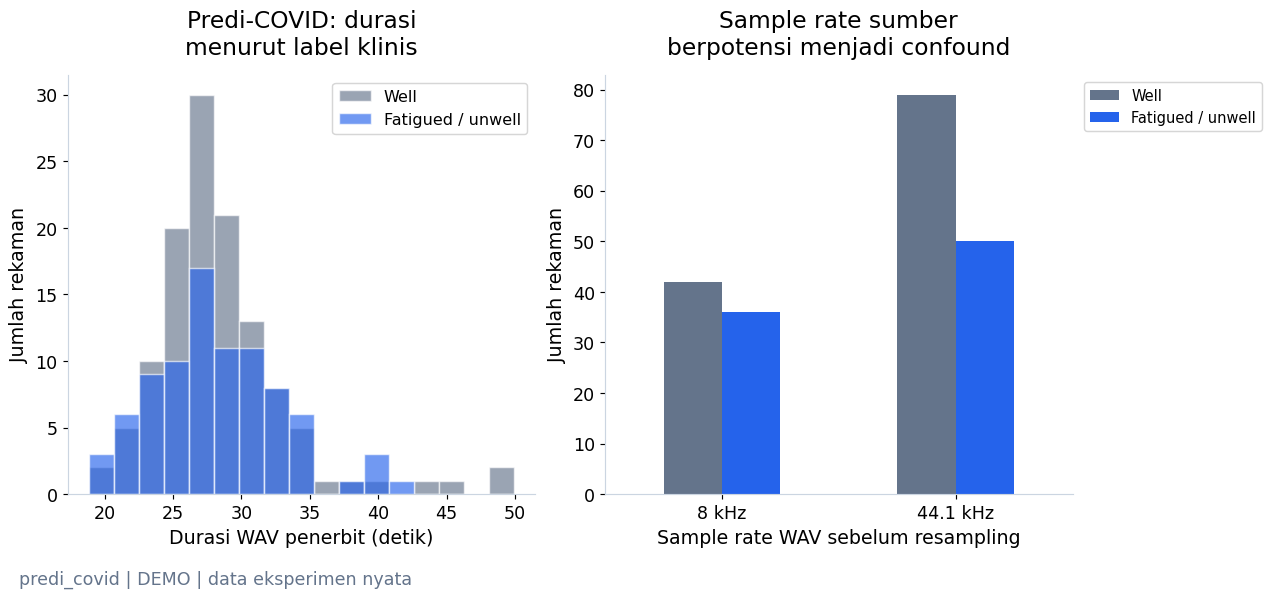

**Yang terlihat:** Durasi dan sample rate sumber bervariasi; seluruh WAV dianalisis pada 16 kHz melalui pipeline yang sama.

**Artinya:** Perbedaan perangkat atau protokol dapat menghasilkan pola suara yang berkorelasi dengan label.

**Perlu diingat:** Resampling 8 kHz ke 16 kHz tidak menciptakan informasi frekuensi baru dan tidak menghapus domain/device confound.

*Sumber: `20261023T105402224766Z_seed42_880107` · REAL / CACHED; inference dihitung ulang.*

Peserta dengan dua label berbeda pada subset: 14


In [24]:
if PREDI_AVAILABLE:
    fig,axes = plt.subplots(1,2,figsize=(12,5.2),layout='constrained')
    bins = np.linspace(predi_data.duration_seconds.min(),predi_data.duration_seconds.max(),18)
    for label,description,color in [(0,'Well',COLORS['secondary']),(1,'Fatigued / unwell',COLORS['audio'])]:
        subset = predi_data[predi_data.target_value.eq(label)]
        axes[0].hist(subset.duration_seconds,bins=bins,alpha=.65,color=color,label=description,edgecolor='white')
    axes[0].set(xlabel='Durasi WAV penerbit (detik)',ylabel='Jumlah rekaman',title='Predi-COVID: durasi\nmenurut label klinis')
    axes[0].legend(loc='upper right',fontsize=11)
    rates = pd.crosstab(predi_data.source_sample_rate,predi_data.target_value).rename(columns={0:'Well',1:'Fatigued / unwell'})
    rates.index = rates.index.map(lambda rate:f'{rate/1000:g} kHz')
    rates.plot.bar(ax=axes[1],rot=0,color=[COLORS['secondary'],COLORS['audio']])
    axes[1].set(xlabel='Sample rate WAV sebelum resampling',ylabel='Jumlah rekaman',title='Sample rate sumber\nberpotensi menjadi confound')
    axes[1].legend(loc='upper left',bbox_to_anchor=(1.01,1),fontsize=10)
    predi_book.show(fig,'predi_audio_qc',
                    'Durasi dan sample rate sumber bervariasi; seluruh WAV dianalisis pada 16 kHz melalui pipeline yang sama.',
                    'Perbedaan perangkat atau protokol dapat menghasilkan pola suara yang berkorelasi dengan label.',
                    'Resampling 8 kHz ke 16 kHz tidak menciptakan informasi frekuensi baru dan tidak menghapus domain/device confound.')
    print('Peserta dengan dua label berbeda pada subset:',int(predi_data.groupby('subject_id').target_value.nunique().gt(1).sum()))

### 7.2 Melihat angka yang benar-benar masuk classifier

**Pertanyaan:** apa bentuk input model, bukan hanya jumlah fiturnya?
Satu baris adalah satu rekaman; satu kolom adalah satu ukuran suara. **X** berisi ukuran suara, sedangkan **y** berisi label asli.
ID peserta, nama file, timestamp, jenis kelamin dan label tidak masuk X. Mereka hanya dipakai untuk audit serta split.

eGeMAPSv02 Functionals menetapkan **88 ringkasan**: nada/F0, loudness, kualitas suara, formant/resonansi, spektrum,
dan durasi voiced segments. Pengelompokan berikut hanya menjelaskan schema; bukan fitur tambahan atau bukti sebab-akibat.
[Dokumentasi openSMILE](https://audeering.github.io/opensmile-python/usage.html) mendefinisikan feature set yang kita pakai.
MFCC memakai frame FFT 2.048 sampel (128 ms) dan hop 512 sampel (32 ms) pada 16 kHz; eGeMAPS memiliki konfigurasi frame internalnya sendiri.

,Split,X.shape,y.shape,Peserta
0,train,"(129, 114)","(129,)",76
1,validation,"(36, 114)","(36,)",20
2,test,"(42, 114)","(42,)",24


target_value,Well,Fatigued/unwell
split,,
test,24,18
train,83,46
validation,14,22


Kolom,Kelompok
egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile20.0,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile80.0,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope,Nada / F0
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope,Nada / F0


,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,egemaps__loudness_sma3_meanRisingSlope,egemaps__shimmerLocaldB_sma3nz_amean,egemaps__F2bandwidth_sma3nz_amean,egemaps__slopeV500-1500_sma3nz_amean,egemaps__spectralFluxUV_sma3nz_amean,mfcc_08_mean,mfcc_12_std
0,33.729568,10.739626,0.860152,1110.624146,-0.015927,0.290012,-7.298480,8.475465
1,34.182579,8.028002,0.877442,1080.345825,-0.005988,0.149546,-12.398511,8.250028
2,36.803661,10.076185,0.971310,1155.729492,-0.015050,0.175837,-18.179502,7.620835


REAL / FRESH: tiga baris awal training; delapan kolom tersebar, bukan seluruh cache peserta.


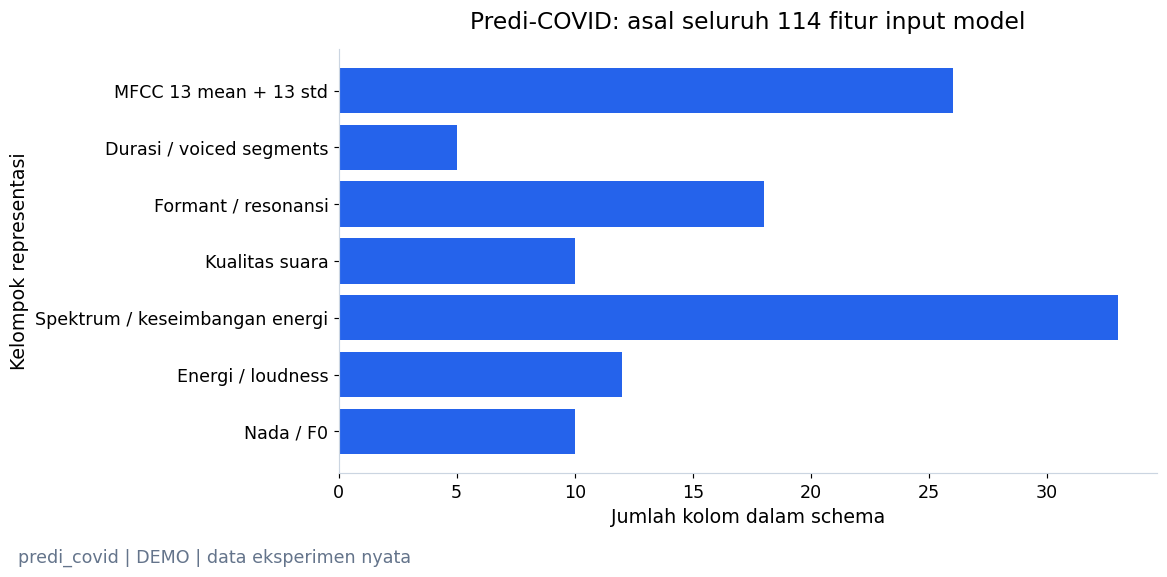

**Yang terlihat:** Schema memuat 88 eGeMAPS dan 26 MFCC.

**Artinya:** Setiap kelompok mengukur aspek suara berbeda, dengan unit fisik atau komputasi berbeda.

**Perlu diingat:** Jumlah fitur tidak menyatakan pentingnya fitur; kelompok penjelasan bukan hasil feature selection.

*Sumber: `20261023T105402224766Z_seed42_880107` · REAL / CACHED; inference dihitung ulang.*

In [25]:
if PREDI_AVAILABLE:
    from IPython.display import HTML
    from html import escape
    X_audio_train = predi_data[predi_data.split.eq('train')][audio_columns]
    y_audio_train = predi_data[predi_data.split.eq('train')].target_value
    matrix_shapes = [{'Split':part,'X.shape':str((len(predi_data[predi_data.split.eq(part)]),len(audio_columns))),
                       'y.shape':str(predi_data[predi_data.split.eq(part)].target_value.shape),
                       'Peserta':predi_data[predi_data.split.eq(part)].subject_id.nunique()} for part in ['train','validation','test']]
    display(pd.DataFrame(matrix_shapes))
    display(pd.crosstab(predi_data.split,predi_data.target_value).rename(columns={0:'Well',1:'Fatigued/unwell'}))
    schema = pd.DataFrame({'Kolom':audio_columns,'Kelompok':[audio_feature_group(name) for name in audio_columns]})
    display(HTML('<details><summary>Buka daftar lengkap '+str(len(schema))+' kolom input</summary>'+schema.to_html(index=False)+'</details>'))
    display(X_audio_train.iloc[:3,np.linspace(0,len(audio_columns)-1,8,dtype=int)].reset_index(drop=True))
    print('REAL / '+source_state+': tiga baris awal training; delapan kolom tersebar, bukan seluruh cache peserta.')
    fig,ax = plt.subplots(figsize=(11,5),layout='constrained')
    counts = schema.groupby('Kelompok',sort=False).size()
    ax.barh(counts.index,counts.values,color=COLORS['audio'])
    ax.set(xlabel='Jumlah kolom dalam schema',ylabel='Kelompok representasi',title='Predi-COVID: asal seluruh 114 fitur input model')
    predi_book.show(fig,'schema_114_audio',f'Schema memuat {sum(name.startswith("egemaps__") for name in audio_columns)} eGeMAPS dan 26 MFCC.',
                    'Setiap kelompok mengukur aspek suara berbeda, dengan unit fisik atau komputasi berbeda.',
                    'Jumlah fitur tidak menyatakan pentingnya fitur; kelompok penjelasan bukan hasil feature selection.')

### 7.2 Tiga baseline, tanpa pencarian parameter pada test

**Dummy mayoritas** mengukur hasil jika model selalu menebak kelas paling banyak.
**Logistic Regression** memperkirakan hubungan linier fitur dengan kelas; **Linear SVM** mencari batas pemisah linier.
Keduanya memakai `C=1` dan bobot kelas seimbang yang ditetapkan sebelum evaluasi.
Imputasi median dan standardisasi berada di dalam pipeline, lalu di-fit **hanya** pada training.
Jenis kelamin, ID, tanggal, format perangkat, label dan nama file tidak menjadi input model: input hanya 114 fitur suara.

Outputnya berupa model tersimpan, prediksi validation/test, confusion matrix, Macro F1, balanced accuracy, serta recall per kelas.
Satu skor tinggi pun belum membuktikan bahwa pola yang dipelajari khusus fatigue; pola penyakit dan protokol dapat ikut terbaca.

,macro_f1,balanced_accuracy,accuracy
dummy_majority,0.363636,0.5,0.571429
logistic_c1,0.485714,0.486111,0.5
linear_svm_c1,0.525847,0.527778,0.547619


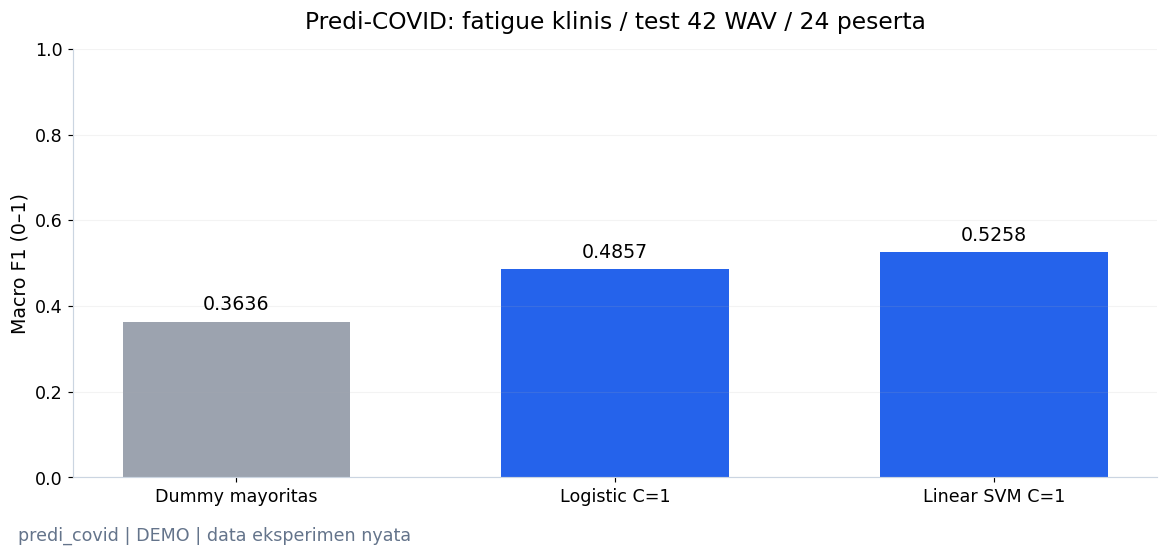

**Yang terlihat:** Ketiga model dievaluasi pada rekaman dan peserta test yang sama; semua skor berasal dari prediksi tersimpan.

**Artinya:** Macro F1 perlu dibaca bersama balanced accuracy: menebak kedua kelas dapat menaikkan F1 tanpa akurasi seimbang yang kuat.

**Perlu diingat:** Tidak ada tuning test; ukuran test kecil dan rekaman berulang membatasi kekuatan kesimpulan.

*Sumber: `20261023T105402224766Z_seed42_880107` · REAL / CACHED; inference dihitung ulang.*

**Interpretasi hasil yang dijalankan:** Logistic memiliki balanced accuracy 0.4861,
    dibandingkan Dummy 0.5000; Linear SVM = 0.5278.
    Kenaikan Macro F1 tidak cukup untuk menyatakan model kuat: balanced accuracy model linear masih dekat 0,5 pada 42 rekaman / 24 peserta test.
    Dengan dua kelas, 0,5 adalah acuan tebakan konstan pada balanced accuracy. Hasil ini belum menjadi bukti biomarker fatigue yang dapat digeneralisasi.
    Tidak dilakukan tuning untuk menaikkan angka test.

In [26]:
if PREDI_AVAILABLE:
    from sklearn.dummy import DummyClassifier
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import LinearSVC
    if RUN_MODE == 'FULL':
        predi_run.write('protocol.json',{'task':'reading_only','seed':42,'test_subject_fraction':.2,
                     'validation_fraction_of_remaining_subjects':.2,'feature_count':114,
                     'models':['dummy_most_frequent','logistic_C1_balanced','linear_svm_C1_balanced'],
                     'preprocessing':'median + StandardScaler fitted on train only','test_tuning':False,
                     'label_1':'fatigued OR unwell; same-day publisher label','selection_uses_model_scores':False})
        predi_scores,predi_prediction_parts = {},[]
        predi_estimators = {
            'dummy_majority':DummyClassifier(strategy='most_frequent'),
            'logistic_c1':LogisticRegression(C=1,class_weight='balanced',max_iter=2000,random_state=config['seed']),
            'linear_svm_c1':LinearSVC(C=1,class_weight='balanced',dual='auto',max_iter=20000,random_state=config['seed'])}
        training = predi_data[predi_data.split.eq('train')]
        for name,estimator in predi_estimators.items():
            model = make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),estimator)
            model.fit(training[audio_columns],training.target_value)
            save_model(predi_run,name,model,audio_columns,predi_data[~predi_data.split.eq('train')])
            predi_scores[name] = {'reload_verified':True,'feature_count':len(audio_columns)}
            for partition in ['validation','test']:
                holdout = predi_data[predi_data.split.eq(partition)]
                predicted = model.predict(holdout[audio_columns])
                predi_scores[name][partition] = classification_metrics(holdout.target_value,predicted,[0,1])
                predi_prediction_parts.append(prediction_table(holdout,predicted,name))
        predi_predictions = pd.concat(predi_prediction_parts,ignore_index=True)
        predi_predictions.to_csv(predi_run.file('predictions/holdout_predictions.csv'),index=False)
        predi_metrics = metrics_base(predi_run,predi_scores,predi_sizes,{'0':'well','1':'fatigued OR unwell'},'dummy_majority')
        predi_metrics['scope'] = 'clinical_fatigue_subset_benchmark; not_occupational_ATC_fatigue'
    else:
        predi_predictions = pd.read_csv(predi_run.path/'predictions/holdout_predictions.csv',dtype={'subject_id':str})
        for name in predi_metrics['models']:
            verify_cached_predictions(predi_run,predi_data[predi_data.split.eq('test')],predi_predictions,name)
    predi_test_scores = {name:value['test'] for name,value in predi_metrics['models'].items()}
    display(pd.DataFrame(predi_test_scores).T[['macro_f1','balanced_accuracy','accuracy']])
    fig = model_bars(predi_test_scores,'macro_f1',
                     f'Predi-COVID: fatigue klinis / test {predi_sizes["test"]} WAV / {predi_data[predi_data.split.eq("test")].subject_id.nunique()} peserta',
                     'Macro F1 (0–1)',COLORS['audio'])
    fig.axes[0].set_xticks(fig.axes[0].get_xticks(),labels=['Dummy mayoritas','Logistic C=1','Linear SVM C=1'])
    fig.axes[0].set_ylim(0,1)
    predi_book.show(fig,'predi_model_comparison',
                    'Ketiga model dievaluasi pada rekaman dan peserta test yang sama; semua skor berasal dari prediksi tersimpan.',
                    'Macro F1 perlu dibaca bersama balanced accuracy: menebak kedua kelas dapat menaikkan F1 tanpa akurasi seimbang yang kuat.',
                    'Tidak ada tuning test; ukuran test kecil dan rekaman berulang membatasi kekuatan kesimpulan.')
    display(Markdown(f"""**Interpretasi hasil yang dijalankan:** Logistic memiliki balanced accuracy {predi_test_scores['logistic_c1']['balanced_accuracy']:.4f},
    dibandingkan Dummy {predi_test_scores['dummy_majority']['balanced_accuracy']:.4f}; Linear SVM = {predi_test_scores['linear_svm_c1']['balanced_accuracy']:.4f}.
    Kenaikan Macro F1 tidak cukup untuk menyatakan model kuat: balanced accuracy model linear masih dekat 0,5 pada {predi_sizes['test']} rekaman / 24 peserta test.
    Dengan dua kelas, 0,5 adalah acuan tebakan konstan pada balanced accuracy. Hasil ini belum menjadi bukti biomarker fatigue yang dapat digeneralisasi.
    Tidak dilakukan tuning untuk menaikkan angka test."""))

### 7.3 Dari nilai mentah ke input setelah imputasi dan scaling

**Imputasi** mengisi nilai hilang menggunakan median training. **Scaling** mengurangi rerata training dan membagi simpangan bakunya,
agar angka berunit besar tidak mendominasi hanya karena skalanya. Test tidak ikut menentukan median/rerata tersebut.
Nilai setelah scaling adalah satuan relatif terhadap training, bukan skor fatigue.

Kita membuka checkpoint Logistic C=1 yang baru dilatih (FULL) atau diverifikasi (DEMO), lalu memanggil transform miliknya.
Tabel contoh di bawah dan prediksi berasal dari baris test yang sama, dipilih menurut sample ID paling awal.

,feature,raw,transformed
0,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,23.9642,-1.3304
7,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevRis...,248.8688,0.1119
15,egemaps__loudness_sma3_pctlrange0-2,0.6280,-0.8200
22,egemaps__mfcc1_sma3_amean,23.8687,-0.4845
30,egemaps__jitterLocal_sma3nz_amean,0.0221,0.2307
37,egemaps__logRelF0-H1-H2_sma3nz_stddevNorm,1.1200,0.0798
45,egemaps__F1amplitudeLogRelF0_sma3nz_stddevNorm,-0.8039,1.1563
52,egemaps__F3frequency_sma3nz_amean,2705.5051,-0.5770
60,egemaps__hammarbergIndexV_sma3nz_amean,29.6007,0.6888
67,egemaps__spectralFluxV_sma3nz_stddevNorm,0.7653,2.0525


,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope,egemaps__loudness_sma3_pctlrange0-2,egemaps__mfcc1_sma3_amean,egemaps__jitterLocal_sma3nz_amean,egemaps__logRelF0-H1-H2_sma3nz_stddevNorm,egemaps__F1amplitudeLogRelF0_sma3nz_stddevNorm,egemaps__F3frequency_sma3nz_amean,egemaps__hammarbergIndexV_sma3nz_amean,egemaps__spectralFluxV_sma3nz_stddevNorm,egemaps__mfcc4V_sma3nz_stddevNorm,egemaps__VoicedSegmentsPerSec,mfcc_02_mean,mfcc_09_mean,mfcc_04_std,mfcc_12_std
0,0.763,-0.866,0.500,-0.623,-1.298,0.078,-0.536,-0.589,-0.208,0.596,-0.084,0.009,0.394,0.369,-1.751,-0.395
1,0.860,-0.735,-1.521,-0.704,-1.178,0.078,-0.991,-0.903,-0.459,0.943,4.182,0.853,0.212,0.466,-1.215,-0.592
2,1.421,-0.734,-0.632,0.024,-1.050,0.078,-0.586,2.520,1.726,-0.462,-0.004,0.073,0.169,-0.465,-0.298,-1.142


Missing cells X_train: 0 ; preprocessing menggunakan parameter training saja.


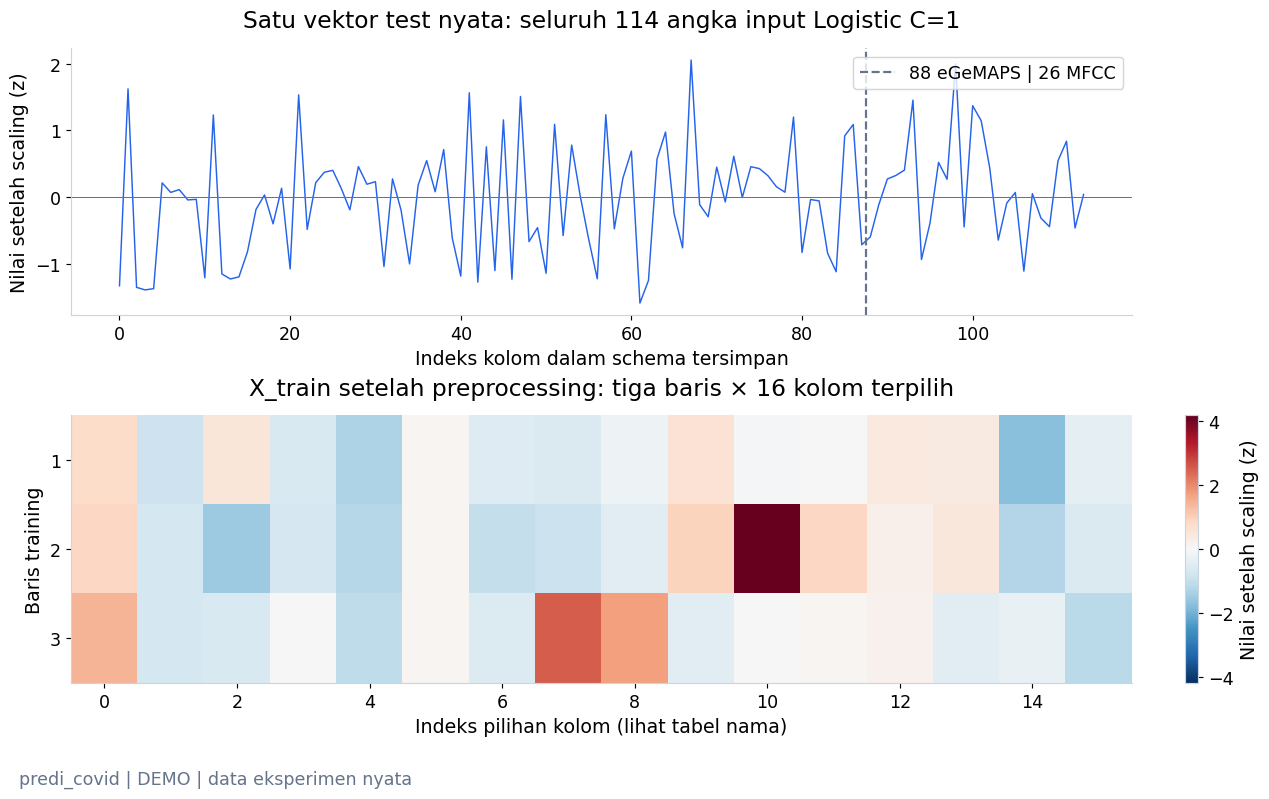

**Yang terlihat:** Vektor lengkap test dan cuplikan matriks training ditransformasi oleh pipeline tersimpan yang sama dengan classifier.

**Artinya:** Model menerima angka ini; batas eGeMAPS/MFCC memperjelas concatenation 88+26 tanpa metadata peserta.

**Perlu diingat:** Scaling tidak menghapus confound, dan satu contoh tidak menjelaskan perilaku seluruh peserta.

*Sumber: `20261023T105402224766Z_seed42_880107` · REAL / CACHED; inference dihitung ulang.*

In [27]:
if PREDI_AVAILABLE:
    import joblib
    predi_bundle = joblib.load(predi_run.path/'models/logistic_c1.joblib')
    predi_training = predi_data[predi_data.split.eq('train')]
    predi_holdout = predi_data[predi_data.split.eq('test')]
    audio_input_view = inspect_model_input(predi_bundle['model'],predi_training,predi_holdout,audio_columns)
    display(audio_input_view['example_vector'].iloc[audio_input_view['selected_indices']].round(4))
    display(audio_input_view['transformed_preview'].round(3))
    print('Missing cells X_train:',audio_input_view['raw_missing_cells'],'; preprocessing menggunakan parameter training saja.')
    fig,axes = plt.subplots(2,1,figsize=(12,7),layout='constrained')
    vector = audio_input_view['example_vector'].transformed.to_numpy()
    axes[0].plot(np.arange(len(vector)),vector,color=COLORS['audio'],lw=1)
    axes[0].axvline(87.5,color=COLORS['secondary'],ls='--',label='88 eGeMAPS | 26 MFCC')
    axes[0].axhline(0,color=COLORS['secondary'],lw=.7)
    axes[0].set(xlabel='Indeks kolom dalam schema tersimpan',ylabel='Nilai setelah scaling (z)',title='Satu vektor test nyata: seluruh 114 angka input Logistic C=1')
    axes[0].legend(loc='upper right')
    preview = audio_input_view['transformed_preview'].to_numpy()
    limit = max(1,float(np.max(np.abs(preview))))
    image = axes[1].imshow(preview,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
    axes[1].set(xlabel='Indeks pilihan kolom (lihat tabel nama)',ylabel='Baris training',yticks=[0,1,2],yticklabels=['1','2','3'],title='X_train setelah preprocessing: tiga baris × 16 kolom terpilih')
    fig.colorbar(image,ax=axes[1],label='Nilai setelah scaling (z)')
    predi_book.show(fig,'actual_audio_model_input',
                    'Vektor lengkap test dan cuplikan matriks training ditransformasi oleh pipeline tersimpan yang sama dengan classifier.',
                    'Model menerima angka ini; batas eGeMAPS/MFCC memperjelas concatenation 88+26 tanpa metadata peserta.',
                    'Scaling tidak menghapus confound, dan satu contoh tidak menjelaskan perilaku seluruh peserta.')

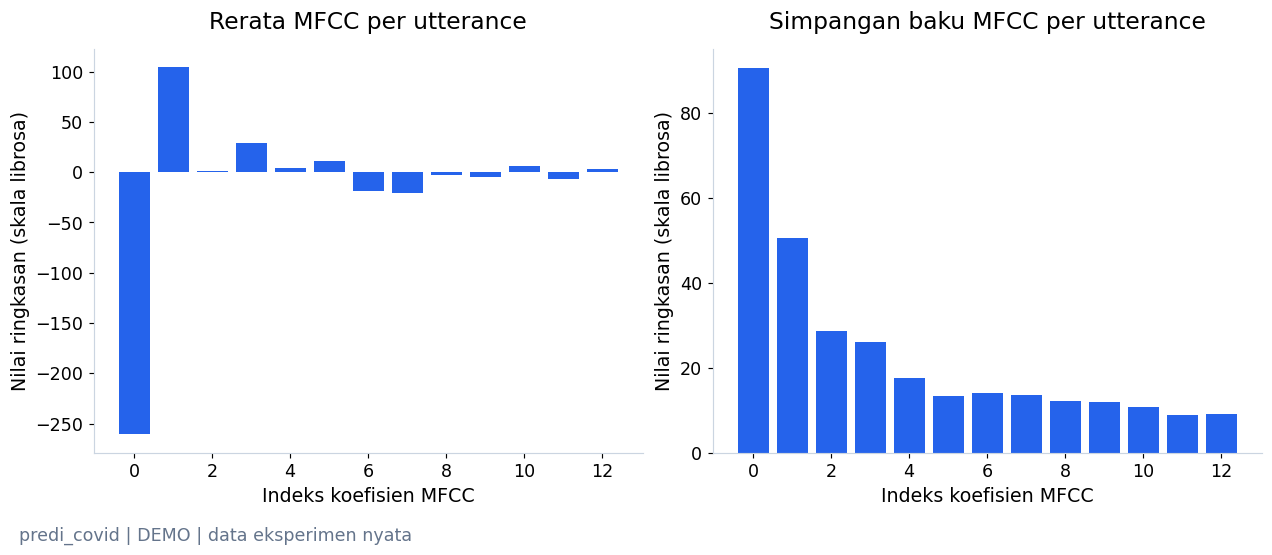

**Yang terlihat:** Masing-masing grafik memiliki 13 angka nyata; keduanya membentuk 26 kolom dari rekaman test yang sama.

**Artinya:** Rerata menunjukkan pusat nilai tiap koefisien, sedangkan std merangkum variasinya sepanjang rekaman.

**Perlu diingat:** Ringkasan menghilangkan urutan temporal; koefisien tidak memiliki arti tunggal sebagai tingkat fatigue.

*Sumber: `20261023T105402224766Z_seed42_880107` · REAL / CACHED; inference dihitung ulang.*

In [28]:
if PREDI_AVAILABLE:
    selected_audio = predi_holdout.sort_values('sample_id').iloc[0]
    fig,axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
    for ax,stat,title in zip(axes,['mean','std'],['Rerata MFCC per utterance','Simpangan baku MFCC per utterance']):
        values = [selected_audio[f'mfcc_{index:02d}_{stat}'] for index in range(13)]
        ax.bar(np.arange(13),values,color=COLORS['audio'])
        ax.set(xlabel='Indeks koefisien MFCC',ylabel='Nilai ringkasan (skala librosa)',title=title)
    predi_book.show(fig,'mfcc_summary_26',
                    'Masing-masing grafik memiliki 13 angka nyata; keduanya membentuk 26 kolom dari rekaman test yang sama.',
                    'Rerata menunjukkan pusat nilai tiap koefisien, sedangkan std merangkum variasinya sepanjang rekaman.',
                    'Ringkasan menghilangkan urutan temporal; koefisien tidak memiliki arti tunggal sebagai tingkat fatigue.')

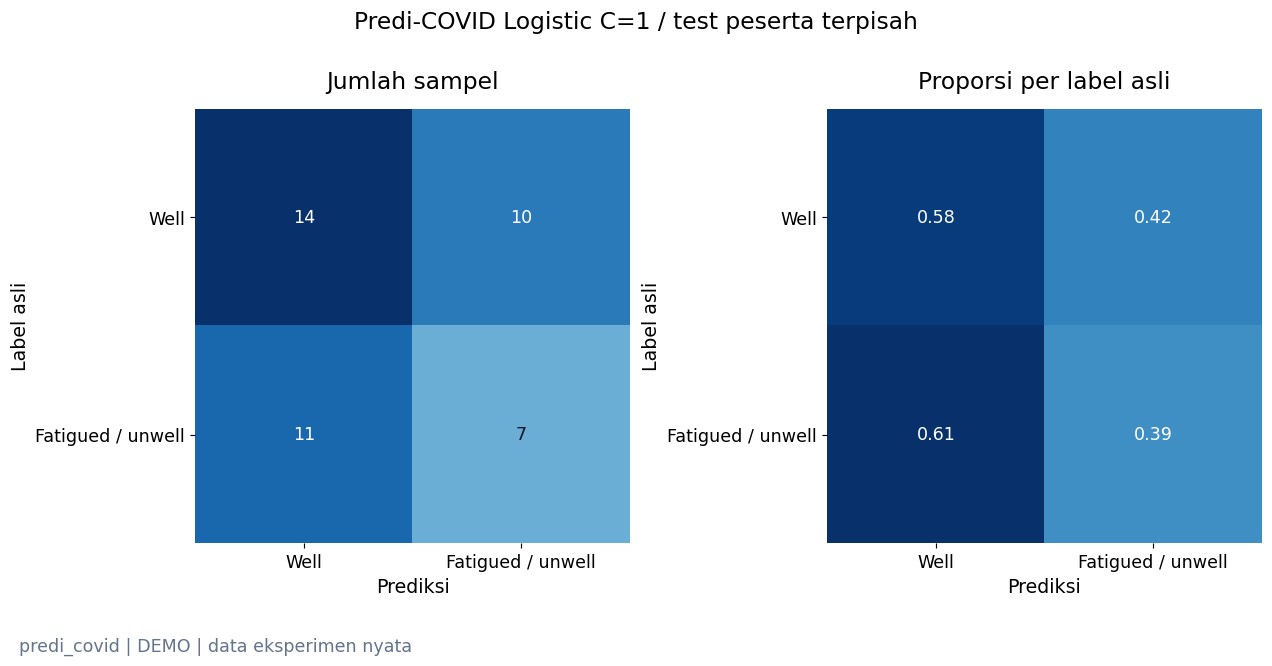

**Yang terlihat:** Confusion matrix berjumlah 42 rekaman; sisi kanan dinormalisasi berdasarkan kelas asli.

**Artinya:** Recall kelas 1 menunjukkan proporsi laporan fatigued/unwell yang ditemukan, sementara kelas 0 memeriksa false alarms.

**Perlu diingat:** Logistic dipilih sebagai baseline interpretabel sebelum melihat skor, bukan sebagai pemenang test.

*Sumber: `20261023T105402224766Z_seed42_880107` · REAL / CACHED; inference dihitung ulang.*

,precision,recall,f1-score,support
Well,0.560000,0.583333,0.571429,24.0
Fatigued / unwell,0.411765,0.388889,0.400000,18.0


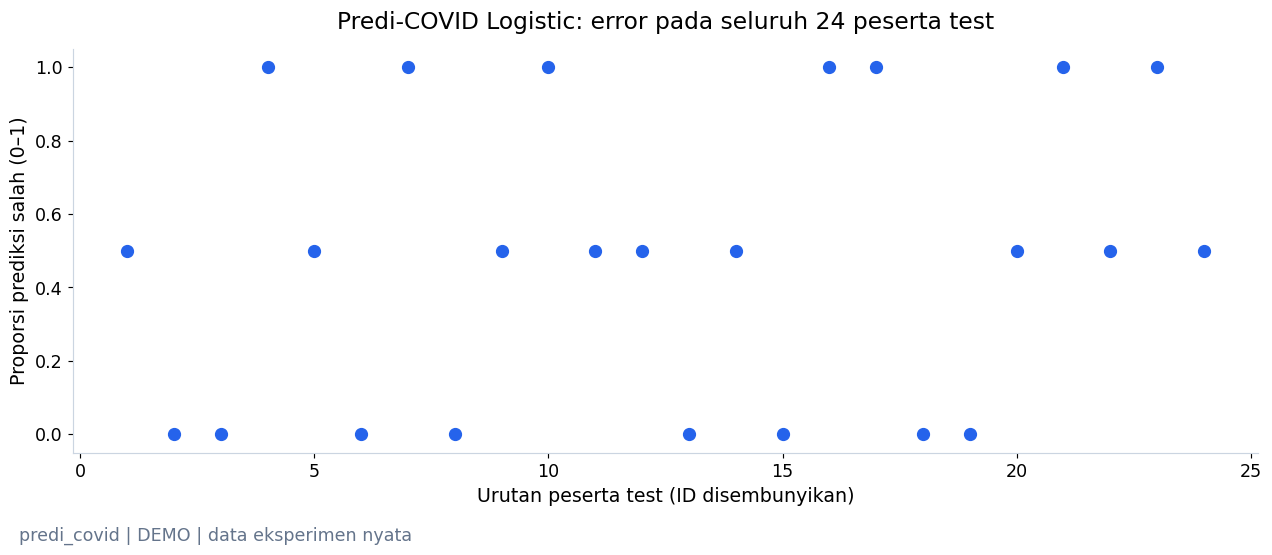

**Yang terlihat:** 21 dari 42 rekaman test salah; semua peserta ditampilkan tanpa seleksi hasil terbaik.

**Artinya:** Error dapat terkonsentrasi pada orang tertentu; ringkasan klip saja menyembunyikan variasi tersebut.

**Perlu diingat:** Hanya satu atau dua rekaman per peserta; error 0 atau 1 bukan estimasi presisi tentang kemampuan individual.

*Sumber: `20261023T105402224766Z_seed42_880107` · REAL / CACHED; inference dihitung ulang.*

Rerata error per peserta: 0.4792


Rekaman  Peserta  \
source_format sex_metadata source_sample_rate                     
3gp           M            8000                     17        9   
              W            8000                      8        5   
m4a           M            44100                    10        6   
              W            44100                     7        4   

                                               Proporsi_error  
source_format sex_metadata source_sample_rate                  
3gp           M            8000                         0.529  
              W            8000                         0.500  
m4a           M            44100                        0.500  
              W            44100                        0.429

Kelompok perangkat/demografi kecil dan tidak diacak. Perbedaan error ini bersifat deskriptif, tidak mengidentifikasi sebab atau membuktikan fairness.

In [29]:
if PREDI_AVAILABLE:
    predi_result = predi_test_scores['logistic_c1']
    fig = confusion_pair(predi_result,['Well','Fatigued / unwell'],'Predi-COVID Logistic C=1 / test peserta terpisah')
    predi_book.show(fig,'predi_confusion',
                    f'Confusion matrix berjumlah {predi_sizes["test"]} rekaman; sisi kanan dinormalisasi berdasarkan kelas asli.',
                    'Recall kelas 1 menunjukkan proporsi laporan fatigued/unwell yang ditemukan, sementara kelas 0 memeriksa false alarms.',
                    'Logistic dipilih sebagai baseline interpretabel sebelum melihat skor, bukan sebagai pemenang test.')
    display(pd.DataFrame({label:predi_result['classification_report'][str(value)]
                          for value,label in [(0,'Well'),(1,'Fatigued / unwell')]}).T[['precision','recall','f1-score','support']])
    predi_errors = predi_predictions[predi_predictions.model.eq('logistic_c1') & predi_predictions.split.eq('test')].copy()
    predi_errors['error'] = predi_errors.truth.ne(predi_errors.prediction)
    subject_errors = predi_errors.groupby('subject_id').agg(error_rate=('error','mean'),recordings=('sample_id','size')).sort_index()
    fig,ax = plt.subplots(figsize=(12,4.8),layout='constrained')
    ax.scatter(np.arange(1,len(subject_errors)+1),subject_errors.error_rate,color=COLORS['audio'],s=65)
    ax.set(xlabel='Urutan peserta test (ID disembunyikan)',ylabel='Proporsi prediksi salah (0–1)',ylim=(-.05,1.05),
           title=f'Predi-COVID Logistic: error pada seluruh {len(subject_errors)} peserta test')
    predi_book.show(fig,'predi_error_per_subject',
                    f'{int(predi_errors.error.sum())} dari {len(predi_errors)} rekaman test salah; semua peserta ditampilkan tanpa seleksi hasil terbaik.',
                    'Error dapat terkonsentrasi pada orang tertentu; ringkasan klip saja menyembunyikan variasi tersebut.',
                    'Hanya satu atau dua rekaman per peserta; error 0 atau 1 bukan estimasi presisi tentang kemampuan individual.')
    print('Rerata error per peserta:',round(subject_errors.error_rate.mean(),4))
    stratified_errors = predi_errors.merge(predi_data[['sample_id','source_format','sex_metadata','source_sample_rate']],on='sample_id',validate='one_to_one')
    display(stratified_errors.groupby(['source_format','sex_metadata','source_sample_rate']).agg(
        Rekaman=('sample_id','size'),Peserta=('subject_id','nunique'),Proporsi_error=('error','mean')).round(3))
    display(Markdown('Kelompok perangkat/demografi kecil dan tidak diacak. Perbedaan error ini bersifat deskriptif, tidak mengidentifikasi sebab atau membuktikan fairness.'))
    predi_book.finish()
    if RUN_MODE == 'FULL':
        predi_run.complete(predi_metrics,{'evaluation_rows':len(predi_data),'source_rows':len(predi_manifest),
                           'feature_missing_fraction':float(predi_data[audio_columns].isna().mean().mean()),
                           'quality_counts':predi_data.quality.value_counts().to_dict(),
                           'subject_overlap':0,'checksum_overlap':0,'no_model_based_exclusions':True},warning_records)

### 7.3 Perbandingan yang masuk akal dan batas interpretasi

ATCOSIM menjawab apakah suara domain ATC dapat diolah, sedangkan Predi-COVID menguji hubungan akustik dengan
**label klinis yang tercatat**. Keduanya tidak berbagi target, populasi, bahasa, perangkat atau protokol yang sama.
Karena itu skor Predi-COVID tidak dapat dipindahkan menjadi estimasi performa pada radio ATC.

Ekstraksi 114 fitur juga merangkum satu ujaran menjadi statistik: urutan naik-turunnya suara hilang dan
perubahan fatigue di dalam ujaran tidak dilabeli. Studi lanjutan membutuhkan rekaman operator dengan target fatigue terdefinisi,
label waktu yang sesuai, izin peserta, serta test subjek/sesi independen. Hasil tidak diklaim sebagai diagnosis atau alat operasional.

## 8. Track 1 — Uji ketahanan saluran: original versus radio-style

**Research question:** apakah model yang belajar suara sebelum simulasi tetap bekerja ketika kanal mengubah frekuensi dan noise?
Semua perbandingan memakai rekaman, konten, label dan peserta test **yang sama**. Kata **clean** di sini berarti sebelum transformasi tambahan,
bukan jaminan rekaman bebas noise. Target tetap fatigue/unwell klinis; tidak ada label COVID symptomatic status yang dibuat menjadi fatigue.

| Langkah tetap sebelum evaluasi | Parameter / alasan |
| :--- | :--- |
| Mono dan format | Pipeline canonical 16 kHz; sumber 8 kHz tidak memperoleh informasi frekuensi baru |
| Band-pass | Butterworth orde 4 per rancangan, 300–3.400 Hz; voice-band stress test, bukan spesifikasi receiver ATC yang tervalidasi |
| Implementasi | SOS forward-backward, magnitude efektif dua lintasan; offline/acausal, bukan klaim pemrosesan streaming |
| Gain | −3 dB tetap; attenuasi tambahan hanya bila diperlukan menjaga peak ≤0,98 |
| Noise | Gaussian yang di-band-limit, seed 42 + hash sample ID; SNR primer 20 dB, stress eksploratif 10 dB |
| SNR aktual | Energi reference setelah filter/gain dibanding noise tambahan yang diketahui; tidak mengestimasi noise asli |
| Codec/distorsi | Tidak disimulasikan; tidak mengklaim model codec/radio operasional |

Forward-backward mengikuti [SciPy](https://docs.scipy.org/doc/scipy-1.14.1/reference/generated/scipy.signal.sosfiltfilt.html).
Parameter ini adalah kondisi eksperimen yang ditetapkan sebelum skor baru dilihat.
**Split peserta sudah dibekukan sebelum transformasi.** Turunan satu rekaman tetap pada partisi yang sama.
Augmentation hanya menggandakan input training dengan turunan radio20; jumlah orang independen tidak bertambah.
Test radio adalah alternatif representasi dari 42 recording yang sama, bukan 42 peserta/sampel independen tambahan.

In [30]:
if PREDI_AVAILABLE:
    from atc_fatigue.audio.radio import radio_style,recording_seed,frequency_response
    from atc_fatigue.research.representations import positive_class_score,binary_ranking_metrics
    radio_config = config['radio_channel']
    if RUN_MODE == 'FULL':
        radio_run = Run.create('predi_covid_radio','01_audio_analysis.ipynb',config,predi_manifest,
                               'radio-voiceband-v1;audio-egemapsv02-mfcc13-v1',predi_rights,
                               predi_limits+['offline controlled channel simulation, not validated ATC-radio population transfer',
                                             '20dB primary protocol;10dB exploratory stress; no test-based parameter search'])
        radio_run.features(predi_data,audio_columns,'clean parent features;audio-egemapsv02-mfcc13-v1')
        radio_run.write('parent_experiments.json',{'clean_features_run':predi_run.manifest['run_id'],
                                                 'source_manifest':config['additional_datasets']['predi_manifest']})
        predi_data[['sample_id','subject_id','session_id','target_value','source_checksum','split']].to_csv(
            radio_run.file('split_manifest.csv'),index=False)
    else:
        radio_run,radio_metrics = cached_run('predi_covid_radio',config)
    radio_book = FigureBook(radio_run,RUN_MODE,config)
    run_card(radio_run,RUN_MODE,'Channel robustness dari label klinis; bukan fatigue ATC')

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; inference checkpoint dihitung ulang, tanpa training baru** |
| Run ID sumber | `20261023T105608840284Z_seed42_0d3b34` |
| Status eksperimen sumber | completed |
| Dataset / target | predi_covid / clinical_fatigue_binary |
| Sampel / subjek | 207 / 120 |
| Unit evaluasi | recording; held-out participant |
| Hasil utama | Channel robustness dari label klinis; bukan fatigue ATC |

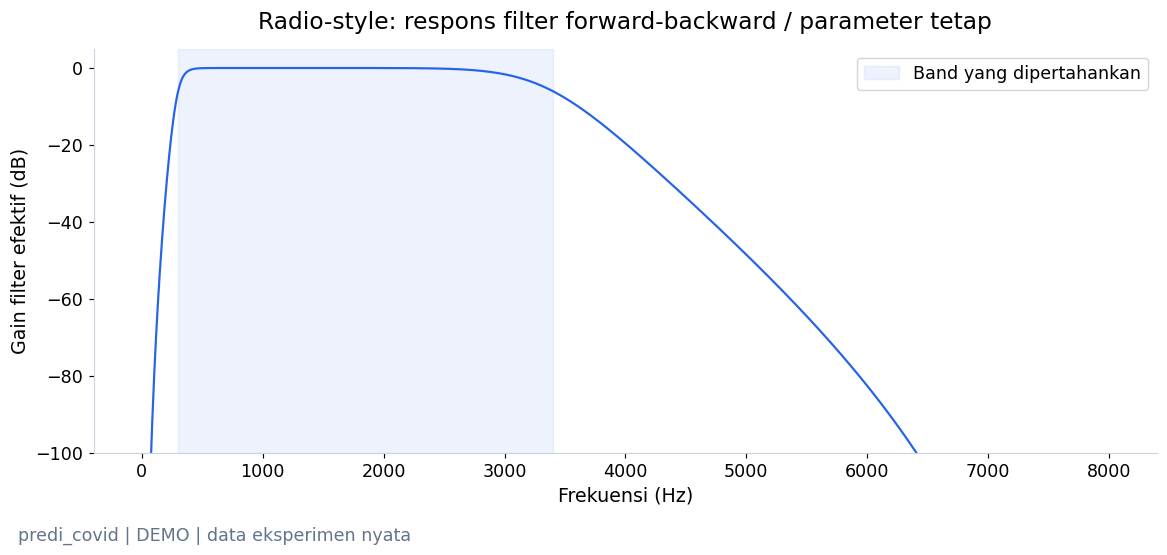

**Yang terlihat:** Band 300–3.400 Hz lebih dipertahankan daripada frekuensi di luar band; kurva dihitung dari koefisien filter aktual.

**Artinya:** Penyaringan mengubah informasi spektral yang diterima extractor, bahkan sebelum noise ditambahkan.

**Perlu diingat:** Kurva ini milik simulasi terkontrol; bukan hasil pengukuran perangkat radio ATC.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · FRESH — respons matematis filter, tanpa media peserta.*

In [31]:
if PREDI_AVAILABLE:
    frequency,response_db = frequency_response(config['audio']['sample_rate'],radio_config)
    fig,ax = plt.subplots(layout='constrained')
    ax.plot(frequency,response_db,color=COLORS['audio'])
    ax.axvspan(*radio_config['band_hz'],color=COLORS['audio'],alpha=.08,label='Band yang dipertahankan')
    ax.set(xlabel='Frekuensi (Hz)',ylabel='Gain filter efektif (dB)',ylim=(-100,5),
           title='Radio-style: respons filter forward-backward / parameter tetap')
    ax.legend(loc='upper right')
    radio_book.show(fig,'radio_filter_response',
                    'Band 300–3.400 Hz lebih dipertahankan daripada frekuensi di luar band; kurva dihitung dari koefisien filter aktual.',
                    'Penyaringan mengubah informasi spektral yang diterima extractor, bahkan sebelum noise ditambahkan.',
                    'Kurva ini milik simulasi terkontrol; bukan hasil pengukuran perangkat radio ATC.',origin='FRESH — respons matematis filter, tanpa media peserta')

### 8.1 Dua player dari satu recording yang sama — contoh publik berizin

Rekaman Predi-COVID yang dipilih deterministik pada test split dirilis sumber sebagai **CC BY4.0**.
Pengguna telah mengizinkan contoh publik; source, credit, perubahan dan checksum tercatat pada [manifest](../../reports/notebook_v3_media_publication.json) dan [galeri media](../../assets/demo_media/README.md).

Gunakan runner `--mode DEMO --private-media --publish-licensed-media --notebook 01_audio_analysis.ipynb`.
`--private-media` menghitung contoh dari sumber lokal; **hanya dua player yang cocok dengan whitelist dan checksum** dipertahankan pada salinan publik.
Media ATCOSIM/MRL/DROZY lain tetap disanitasi. Tidak ada upload dataset/cache penuh.

Kedua player memakai recording yang sama sebelum/sesudah radio20. `normalize=False` mempertahankan perbedaan gain.
Clean berarti canonical mono16kHz sebelum simulasi, bukan file yang dijamin bebas noise.
Jika GitHub menyembunyikan player HTML, [unduh WAV clean](../../assets/demo_media/predi_clean.wav) dan [radio](../../assets/demo_media/predi_radio20.wav).

In [32]:
if PREDI_AVAILABLE:
    if PRIVATE_MEDIA:
        from IPython.display import Audio
        radio_example = predi_data[predi_data.split.eq('test')].sort_values('sample_id').iloc[0]
        source_waveform,source_hz = sf.read(radio_example.original_path,always_2d=True)
        original_example = resample(source_waveform.mean(axis=1),source_hz,config['audio']['sample_rate']).astype(np.float32)
        simulated_example = radio_style(original_example,16000,radio_config,recording_seed(radio_example.sample_id,config['seed']))
        display(Markdown('**Original / Clean Audio — REAL, FRESH lokal; sebelum simulasi**'))
        display(Audio(original_example,rate=16000,normalize=False))
        display(Markdown('**Radio-Style Audio — rekaman yang sama; REAL source + transformasi terkontrol**'))
        display(Audio(simulated_example['signal'],rate=16000,normalize=False))
        display(pd.DataFrame([simulated_example['qc']]))
    else:
        print('Playback privat dinonaktifkan. Tidak ada audio bytes pada output publik.')

**Contoh audio publik berizin — Predi-COVID, CC BY 4.0.** Kedua player berasal dari recording yang sama. Kredit: Abir Elbéji et al.; [sumber](https://zenodo.org/records/5937844) · [lisensi](https://creativecommons.org/licenses/by/4.0/) · [file dan atribusi](../../assets/demo_media/README.md). Clean telah diubah ke mono16kHz; versi radio memakai transformasi terkontrol.

**Original / Clean Audio — REAL, FRESH lokal; sebelum simulasi**

**Radio-Style Audio — rekaman yang sama; REAL source + transformasi terkontrol**

,seed,requested_snr_db,measured_snr_db,gain_db,peak_attenuation,sample_rate,duration_seconds,source_rms,radio_rms,source_peak,radio_peak,source_clipping_fraction,radio_clipping_fraction,source_inband_energy_fraction,radio_inband_energy_fraction,codec_simulated,filter
0,942192710,20.0,20.0,-3.0,1.0,16000,26.968062,0.081702,0.039535,0.98889,0.592004,0.0,0.0,0.484547,0.979695,False,butterworth_sos_forward_backward_offline


In [33]:
if PREDI_AVAILABLE:
    if PRIVATE_MEDIA:
        import librosa
        from atc_fatigue.research.data import pseudonym
        original_spectrum = np.abs(librosa.stft(original_example,n_fft=2048,hop_length=512))
        radio_spectrum = np.abs(librosa.stft(simulated_example['signal'],n_fft=2048,hop_length=512))
        shared_reference = max(float(original_spectrum.max()),float(radio_spectrum.max()))
        fig,axes = plt.subplots(2,2,figsize=(13,8),layout='constrained')
        time_seconds = np.arange(len(original_example))/16000
        amplitude_limit = max(np.max(abs(original_example)),np.max(abs(simulated_example['signal'])))*1.05
        for axis,waveform,title in [(axes[0,0],original_example,'Original / sebelum simulasi'),
                                   (axes[0,1],simulated_example['signal'],'Radio-style / 20 dB')]:
            axis.plot(time_seconds,waveform,color=COLORS['audio'],lw=.6)
            axis.set(xlabel='Waktu recording (detik)',ylabel='Amplitudo relatif',title=title,ylim=(-amplitude_limit,amplitude_limit))
        for axis,spectrum in zip(axes[1],[original_spectrum,radio_spectrum]):
            image = axis.imshow(librosa.amplitude_to_db(spectrum,ref=shared_reference),origin='lower',aspect='auto',
                                extent=[0,len(original_example)/16000,0,8000],vmin=-80,vmax=0,cmap='magma')
            axis.set(xlabel='Waktu recording (detik)',ylabel='Frekuensi (Hz)',title='STFT dengan skala dB dan referensi bersama')
        fig.colorbar(image,ax=list(axes[1]),label='Magnitude relatif referensi bersama (dB)')
        radio_book.show(fig,'radio_actual_waveforms_spectra',
                        'Waveform dan STFT menggunakan satu recording test yang sama, sumbu amplitudo serta color scale yang sama.',
                        'Band-limiting dan noise mengubah tampilan spektrum tanpa mengubah konten atau label klinis.',
                        'Media sumber dan turunannya hanya untuk presentasi lokal sesuai hak akses.',private=True,origin='REAL / FRESH — LOCAL ONLY')
    else:
        print('Waveform/spectrogram recording sumber tidak diekspor ke notebook publik.')

Media sumber hanya tersedia pada salinan eksekusi lokal; output privat dihilangkan dari salinan publik.


In [34]:
if PREDI_AVAILABLE and PRIVATE_MEDIA:
    from scipy.signal import welch
    fig,axis = plt.subplots(figsize=(11,5.2),layout='constrained')
    for waveform,label,color in [(original_example,'Original / canonical mono 16k',COLORS['secondary']),
                                 (simulated_example['signal'],'Radio-style 20 dB',COLORS['audio'])]:
        frequency_hz,density = welch(waveform,fs=16000,nperseg=2048)
        axis.plot(frequency_hz,10*np.log10(np.maximum(density,1e-14)),label=label,color=color,lw=1.4)
    axis.axvspan(*radio_config['band_hz'],color=COLORS['audio'],alpha=.06)
    axis.set(xlabel='Frekuensi (Hz)',ylabel='Power spectral density (dB amplitudo²/Hz)',
             title='Distribusi energi frekuensi / recording test yang sama / lokal saja',xlim=(0,8000))
    axis.legend(loc='lower left')
    radio_book.show(fig,'radio_real_frequency_energy_local',
        'Kurva PSD dihitung dari recording yang sama sebelum/sesudah simulasi, dengan satuan dan sumbu yang sama.',
        'Filter menekan energi di luar voice band; noise tambahan membentuk noise floor terkontrol.',
        'PSD source-derived hanya lokal; perubahan energi ini tidak mengubah label atau menunjukkan fatigue baru.',private=True,origin='REAL / FRESH — LOCAL ONLY')
else:
    print('PSD data asli tidak diekspor; respons filter dan ilustrasi energi sintetis tetap ditampilkan.')

Media sumber hanya tersedia pada salinan eksekusi lokal; output privat dihilangkan dari salinan publik.


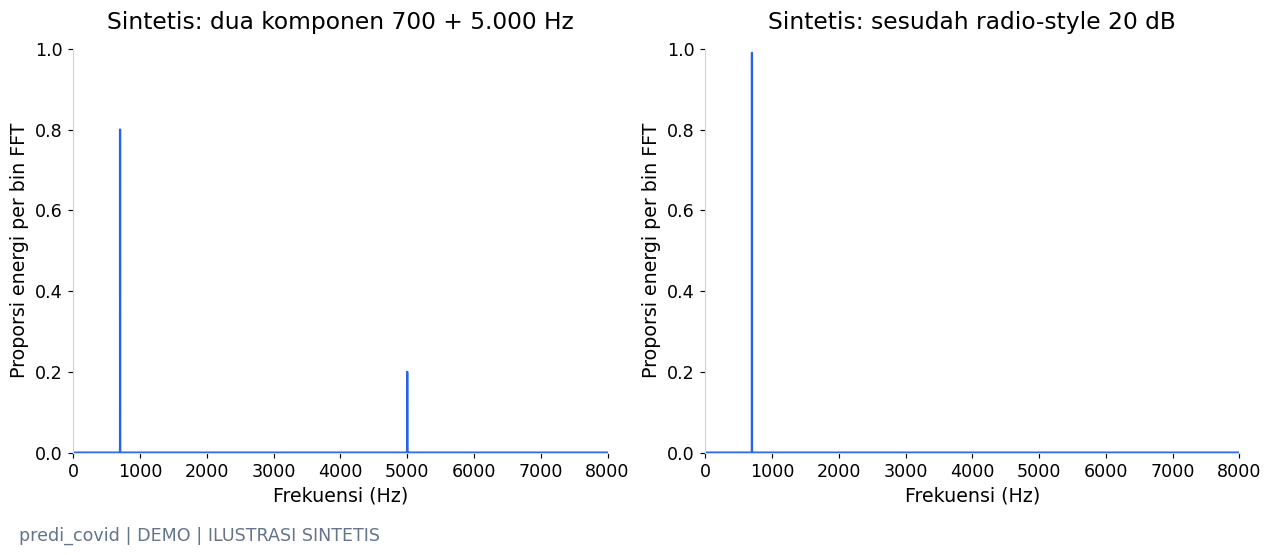

**Yang terlihat:** Komponen 5.000 Hz ditekan oleh filter, sementara komponen 700 Hz tetap terlihat pada ilustrasi ini.

**Artinya:** Ilustrasi memperlihatkan mengapa membatasi bandwidth dapat mengubah fitur spektral.

**Perlu diingat:** Sinyal dibuat secara matematis, bukan suara pasien/ATC; tidak dipakai training atau score benchmark.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

In [35]:
if PREDI_AVAILABLE:
    illustration_time = np.arange(32000)/16000
    illustration_source = .2*np.sin(2*np.pi*700*illustration_time)+.1*np.sin(2*np.pi*5000*illustration_time)
    illustration_radio = radio_style(illustration_source,16000,radio_config,config['seed'])
    fig,axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
    for axis,waveform,title in [(axes[0],illustration_source,'Sintetis: dua komponen 700 + 5.000 Hz'),
                                (axes[1],illustration_radio['signal'],'Sintetis: sesudah radio-style 20 dB')]:
        spectrum = np.abs(np.fft.rfft(waveform))**2
        frequency_hz = np.fft.rfftfreq(len(waveform),1/16000)
        axis.plot(frequency_hz,spectrum/spectrum.sum(),color=COLORS['audio'])
        axis.set(xlabel='Frekuensi (Hz)',ylabel='Proporsi energi per bin FFT',title=title,xlim=(0,8000),ylim=(0,1))
    radio_book.show(fig,'radio_synthetic_energy',
                    'Komponen 5.000 Hz ditekan oleh filter, sementara komponen 700 Hz tetap terlihat pada ilustrasi ini.',
                    'Ilustrasi memperlihatkan mengapa membatasi bandwidth dapat mengubah fitur spektral.',
                    'Sinyal dibuat secara matematis, bukan suara pasien/ATC; tidak dipakai training atau score benchmark.',synthetic=True)

### Perbandingan nyata yang boleh dibagikan

[Source WAV](../../assets/demo_media/predi_source.wav) · [Clean](../../assets/demo_media/predi_clean.wav) · [Radio20](../../assets/demo_media/predi_radio20.wav).

![Predi-COVID REAL / recording yang sama / amplitudo dengan skala bersama](../../assets/demo_media/predi_waveforms.png)

**Yang terlihat:** bentuk ucapan sama, amplitudo berubah karena kanal. **Artinya:** label/konten tidak diganti. **Perlu diingat:** contoh ini bukan tambahan test independen.

![Predi-COVID REAL / STFT reference dan color scale bersama](../../assets/demo_media/predi_spectrograms.png)

**Yang terlihat:** frekuensi di luar band ditekan. **Artinya:** input fitur spektral berubah meskipun sumber/label tetap. **Perlu diingat:** ini simulasi, bukan kanal ATC terukur.

![Predi-COVID REAL / distribusi energi frekuensi](../../assets/demo_media/predi_frequency_energy.png)

**Yang terlihat:** PSD before/after mempunyai satuan yang sama. **Artinya:** perubahan kanal dapat memengaruhi eGeMAPS/MFCC. **Perlu diingat:** magnitude shift bukan tingkat fatigue. **Sumber:** Abir Elbéji et al.(2022), [Zenodo](https://doi.org/10.5281/zenodo.5937844), [CC BY4.0](https://creativecommons.org/licenses/by/4.0/); mono/resampling, simulasi kanal dan visualisasi merupakan adaptasi. [Atribusi lengkap](../../assets/demo_media/README.md).

### 8.2 Ekstraksi turunan radio: label tetap, representasi berubah

FULL membaca setiap WAV berizin, menjalankan pipeline mono/resampling canonical, lalu membuat turunan 20 dB dan 10 dB.
Extractor eGeMAPS/MFCC yang sama menghitung 114 fitur tiap versi. Turunan WAV tidak disimpan; checksum sinyal, parameter,
seed, quality metrics, dan tabel fitur disimpan lokal pada run baru. DEMO membaca tabel yang integrity-nya sudah diverifikasi.

**Tidak ada augmentasi lintas peserta, tidak ada pasangan video palsu, dan tidak ada label baru yang dibuat.**

In [36]:
if PREDI_AVAILABLE:
    if RUN_MODE == 'FULL':
        radio_tables,channel_qc = {},[]
        for condition,snr in [('radio20',radio_config['snr_db']),('radio10',radio_config['stress_snr_db'])]:
            rows = []
            for position,row in enumerate(predi_data.to_dict('records')):
                waveform,rate = sf.read(row['original_path'],always_2d=True)
                prepared = resample(waveform.mean(axis=1),rate,16000).astype(np.float32)
                transformed = radio_style(prepared,16000,radio_config,recording_seed(row['sample_id'],config['seed']),snr_db=snr)
                from atc_fatigue.utils.runtime import checksum
                import hashlib
                features = extract_signal(transformed['signal'],16000,config['audio'])
                rows.append({**row,**features,'channel':condition,'original_source_sample_rate':rate,
                             'transformed_signal_sha256':hashlib.sha256(transformed['signal'].tobytes()).hexdigest()})
                channel_qc.append({'sample_id':row['sample_id'],'subject_id':row['subject_id'],'split':row['split'],
                                   'channel':condition,**transformed['qc']})
                if (position+1)%50==0:print(condition,'extraction',position+1,'/',len(predi_data))
            table = pd.DataFrame(rows)
            if not table.quality.eq('ok').all() or not np.isfinite(table[audio_columns]).all().all():
                raise ValueError('Radio QC failed; no silent exclusions or invented feature values')
            assert table[['sample_id','subject_id','target_value','split']].equals(predi_data[['sample_id','subject_id','target_value','split']])
            table.to_parquet(radio_run.file('features/'+condition+'.parquet'),index=False)
            radio_tables[condition] = table
        radio_quality = pd.DataFrame(channel_qc)
        radio_quality.to_csv(radio_run.file('data_channel_qc.csv'),index=False)
    else:
        radio_tables = {name:pd.read_parquet(radio_run.path/'features'/f'{name}.parquet') for name in ['radio20','radio10']}
        radio_quality = pd.read_csv(radio_run.path/'data_channel_qc.csv')
    channel_tables = {'clean':predi_data,**radio_tables}
    display(radio_quality.groupby('channel').agg(Rekaman=('sample_id','size'),SNR_min_dB=('measured_snr_db','min'),
        SNR_max_dB=('measured_snr_db','max'),RMS_mean=('radio_rms','mean'),Clipping_maks=('radio_clipping_fraction','max'),
        Energi_dalam_band=('radio_inband_energy_fraction','mean')).round(5))
    quality_comparison = []
    for channel,group in radio_quality.groupby('channel'):
        for stage,prefix in [('Original / canonical 16k','source'),('Radio-style','radio')]:
            quality_comparison.append({'Channel':channel,'Tahap':stage,'N recording':len(group),
                'Mean RMS':group[prefix+'_rms'].mean(),'Max peak':group[prefix+'_peak'].max(),
                'Mean in-band energy fraction':group[prefix+'_inband_energy_fraction'].mean(),
                'Max clipping fraction':group[prefix+'_clipping_fraction'].max()})
    display(pd.DataFrame(quality_comparison).round(5))


,Rekaman,SNR_min_dB,SNR_max_dB,RMS_mean,Clipping_maks,Energi_dalam_band
channel,,,,,,
radio10,207,10.0,10.0,0.05346,0.0,0.98100
radio20,207,20.0,20.0,0.05123,0.0,0.98117


,Channel,Tahap,N recording,Mean RMS,Max peak,Mean in-band energy fraction,Max clipping fraction
0,radio10,Original / canonical 16k,207,0.10458,1.11981,0.54454,0.00001
1,radio10,Radio-style,207,0.05346,0.79914,0.98100,0.00000
2,radio20,Original / canonical 16k,207,0.10458,1.11981,0.54454,0.00001
3,radio20,Radio-style,207,0.05123,0.78093,0.98117,0.00000


### 8.3 Training dan evaluasi tiga kondisi primer

1. **Train clean → test clean:** referensi yang sama dengan benchmark klinis sebelumnya.
2. **Train clean → test radio20:** checkpoint yang sama menghadapi perubahan kanal, tanpa dilatih ulang pada test.
3. **Train clean + radio20 → test radio20:** model baru melihat kedua representasi **training participants saja**.

Dummy, Logistic C=1 dan Linear SVM C=1 tetap digunakan. Semua preprocessing fit ulang hanya pada matriks training masing-masing.
Turunan validation/test tidak dimasukkan training dan tidak dihitung sebagai observasi independen baru.
Kondisi radio10 adalah stress analysis tambahan, tanpa pemilihan SNR/parameter berdasarkan skor test.

In [37]:
if PREDI_AVAILABLE:
    if RUN_MODE == 'FULL':
        from sklearn.base import clone
        training_clean = predi_data[predi_data.split.eq('train')]
        training_augmented = pd.concat([training_clean,radio_tables['radio20'][radio_tables['radio20'].split.eq('train')]],ignore_index=True)
        assert set(training_augmented.subject_id)==set(training_clean.subject_id)
        assert not set(training_augmented.subject_id)&set(predi_data[~predi_data.split.eq('train')].subject_id)
        training_augmented[['sample_id','subject_id','split']].to_csv(radio_run.file('augmentation_membership.csv'),index=False)
        radio_run.write('protocol.json',{'conditions':['clean_to_clean','clean_to_radio20','aug20_to_radio20'],
            'stress':['clean_to_radio10','aug20_to_radio10'],'parameters':radio_config,'independent_training_subjects':76,
            'clean_train_rows':len(training_clean),'augmented_train_rows':len(training_augmented),'test_tuning':False,
            'source_split_run':predi_run.manifest['run_id'],'no_extra_independent_test_samples':True})
        radio_models = {}
        for regime,training_frame in [('clean',training_clean),('aug20',training_augmented)]:
            for name,estimator in predi_estimators.items():
                model = make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),clone(estimator))
                model.fit(training_frame[audio_columns],training_frame.target_value)
                artifact = regime+'__'+name
                save_model(radio_run,artifact,model,audio_columns,predi_data[~predi_data.split.eq('train')])
                radio_models[artifact] = model
    else:
        radio_models = {path.stem:joblib.load(path)['model'] for path in (radio_run.path/'models').glob('*.joblib')}

In [38]:
if PREDI_AVAILABLE:
    training_clean = predi_data[predi_data.split.eq('train')]
    training_augmented = pd.concat([training_clean,radio_tables['radio20'][radio_tables['radio20'].split.eq('train')]],ignore_index=True)
    display(pd.DataFrame([{'Training regime':name,'X_train':frame[audio_columns].shape,'y_train':frame.target_value.shape,
        'Independent participants':frame.subject_id.nunique(),'Target 0':int(frame.target_value.eq(0).sum()),'Target 1':int(frame.target_value.eq(1).sum())}
        for name,frame in [('clean',training_clean),('clean + radio20',training_augmented)]]))
    radio_test_frame = radio_tables['radio20'][radio_tables['radio20'].split.eq('test')]
    augmented_view = inspect_model_input(radio_models['aug20__logistic_c1'],training_augmented,radio_test_frame,audio_columns)
    clean_radio_view = inspect_model_input(radio_models['clean__logistic_c1'],training_clean,radio_test_frame,audio_columns)
    contrast = augmented_view['example_vector'].rename(columns={'transformed':'z / fit augmented train'})
    contrast['z / fit clean train'] = clean_radio_view['example_vector'].transformed
    display(contrast.iloc[augmented_view['selected_indices'][:8]].round(4))
    print('Recording radio test sama, tetapi statistik preprocessing berbeda karena training regime berbeda; tidak ada fit pada test.')

,Training regime,X_train,y_train,Independent participants,Target 0,Target 1
0,clean,"(129, 114)","(129,)",76,83,46
1,clean + radio20,"(258, 114)","(258,)",76,166,92


,feature,raw,z / fit augmented train,z / fit clean train
0,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,29.9331,-0.4349,-0.0511
7,egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevRis...,731.6816,1.9789,2.7029
15,egemaps__loudness_sma3_pctlrange0-2,0.3037,-1.3589,-2.5497
22,egemaps__mfcc1_sma3_amean,29.3788,-0.0395,0.0947
30,egemaps__jitterLocal_sma3nz_amean,0.0547,2.2014,6.9973
37,egemaps__logRelF0-H1-H2_sma3nz_stddevNorm,-1.5750,0.0217,0.0656
45,egemaps__F1amplitudeLogRelF0_sma3nz_stddevNorm,-0.7156,1.4151,1.8910
52,egemaps__F3frequency_sma3nz_amean,2880.5659,0.9054,1.7604


Recording radio test sama, tetapi statistik preprocessing berbeda karena training regime berbeda; tidak ada fit pada test.


In [39]:
if PREDI_AVAILABLE:
    radio_conditions = [('clean','clean'),('clean','radio20'),('aug20','radio20'),('clean','radio10'),('aug20','radio10')]
    if RUN_MODE == 'FULL':
        radio_scores,radio_prediction_parts = {},[]
        for regime,evaluation_channel in radio_conditions:
            for name in predi_estimators:
                artifact = regime+'__'+name
                key = regime+'_to_'+evaluation_channel+'__'+name
                model = radio_models[artifact]
                radio_scores[key] = {'reload_verified':True,'artifact':artifact,'evaluation_channel':evaluation_channel,
                                     'training_regime':regime,'base_model':name,'feature_count':len(audio_columns)}
                for partition in ['validation','test']:
                    holdout = channel_tables[evaluation_channel][channel_tables[evaluation_channel].split.eq(partition)]
                    predicted = model.predict(holdout[audio_columns])
                    score = positive_class_score(model,holdout,audio_columns)
                    radio_scores[key][partition] = {**classification_metrics(holdout.target_value,predicted,[0,1]),
                                                    **binary_ranking_metrics(holdout.target_value,score)}
                    radio_prediction_parts.append(prediction_table(holdout,predicted,key,artifact=artifact,
                        evaluation_channel=evaluation_channel,training_regime=regime,score_1=score))
        radio_predictions = pd.concat(radio_prediction_parts,ignore_index=True)
        radio_predictions.to_csv(radio_run.file('predictions/holdout_predictions.csv'),index=False)
        radio_metrics = metrics_base(radio_run,radio_scores,{'train':{'clean':len(training_clean),'augmented_rows':len(training_augmented)},
                         'validation':predi_sizes['validation'],'test':predi_sizes['test']},{'0':'well','1':'fatigued OR unwell'},'clean_to_clean__dummy_majority')
        radio_metrics['scope'] = 'controlled_channel_robustness_clinical_fatigue; not_ATC_transfer'
    else:
        radio_predictions = pd.read_csv(radio_run.path/'predictions/holdout_predictions.csv',dtype={'subject_id':str})
        for key,result in radio_metrics['models'].items():
            test = channel_tables[result['evaluation_channel']]
            verify_cached_predictions(radio_run,test[test.split.eq('test')],radio_predictions[radio_predictions.model.eq(key)],key,result['artifact'])
    radio_score_table = pd.DataFrame([{'Condition':value['training_regime']+' → '+value['evaluation_channel'],
           'Model':value['base_model'],'Macro F1':value['test']['macro_f1'],'Balanced accuracy':value['test']['balanced_accuracy'],
           'Fatigue recall':value['test']['classification_report']['1']['recall'],'ROC-AUC':value['test']['roc_auc'],
           'Average precision':value['test']['average_precision'],'Test recording':radio_metrics['n_test']}
           for value in radio_metrics['models'].values()])
    display(radio_score_table.round(4))
    for name in predi_test_scores:
        result = radio_metrics['models']['clean_to_clean__'+name]['test']
        np.testing.assert_allclose(result['macro_f1'],predi_test_scores[name]['macro_f1'],rtol=1e-12,atol=1e-12)

,Condition,Model,Macro F1,Balanced accuracy,Fatigue recall,ROC-AUC,Average precision,Test recording
0,clean → clean,dummy_majority,0.3636,0.5000,0.0000,0.5000,0.4286,42
1,clean → clean,logistic_c1,0.4857,0.4861,0.3889,0.5648,0.4880,42
2,clean → clean,linear_svm_c1,0.5258,0.5278,0.3889,0.5764,0.4833,42
3,clean → radio20,dummy_majority,0.3636,0.5000,0.0000,0.5000,0.4286,42
4,clean → radio20,logistic_c1,0.6298,0.6458,0.3333,0.6852,0.6889,42
5,clean → radio20,linear_svm_c1,0.5758,0.5764,0.4444,0.6088,0.5297,42
6,aug20 → radio20,dummy_majority,0.3636,0.5000,0.0000,0.5000,0.4286,42
7,aug20 → radio20,logistic_c1,0.5758,0.5764,0.4444,0.6157,0.5367,42
8,aug20 → radio20,linear_svm_c1,0.4815,0.4931,0.2778,0.5417,0.4644,42
9,clean → radio10,dummy_majority,0.3636,0.5000,0.0000,0.5000,0.4286,42


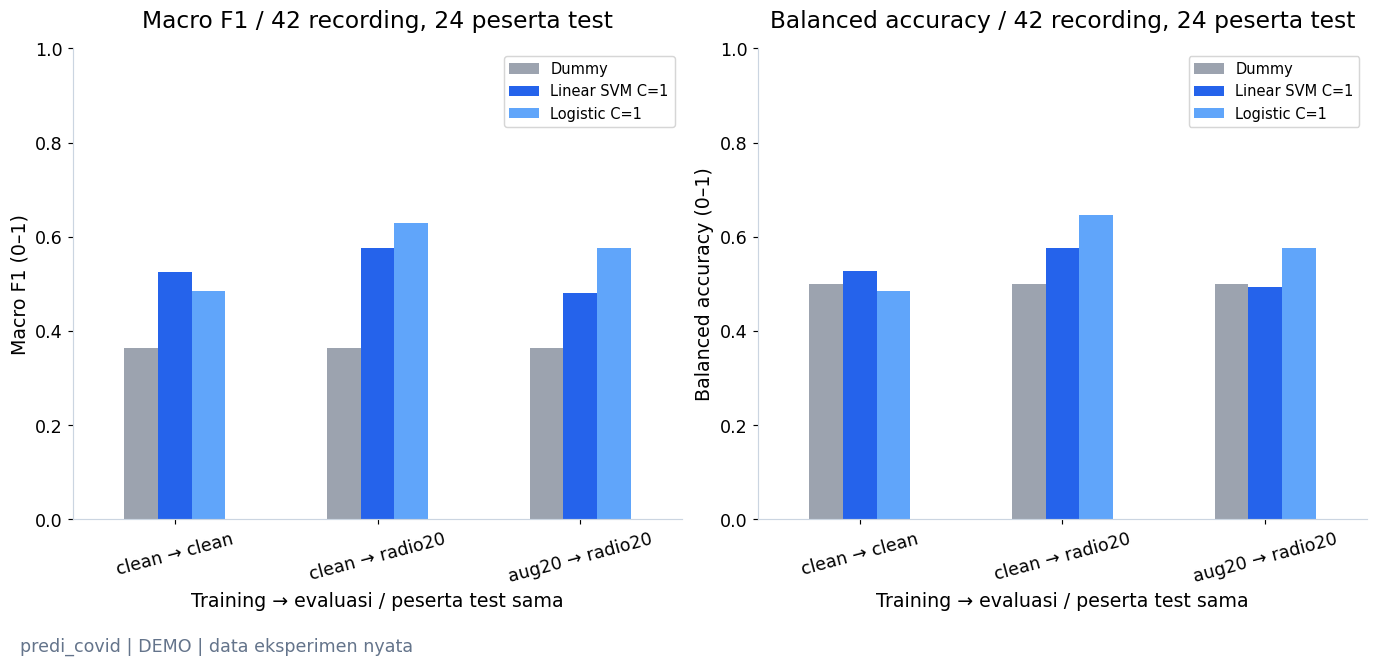

**Yang terlihat:** Semua batang memakai target klinis dan 42 recording test yang sama; kondisi hanya mengubah kanal atau data training yang diizinkan.

**Artinya:** Selisih clean→radio mengukur sensitivitas kanal; augmented→radio menguji apakah paparan kanal saat training membantu.

**Perlu diingat:** Arah perubahan dilaporkan apa adanya. Tambahan 10 dB bersifat eksploratif; bukan bukti transfer ke populasi ATC.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

In [40]:
if PREDI_AVAILABLE:
    primary_order = ['clean → clean','clean → radio20','aug20 → radio20']
    primary_scores = radio_score_table[radio_score_table.Condition.isin(primary_order)]
    fig,axes = plt.subplots(1,2,figsize=(13,5.8),layout='constrained')
    labels = {'dummy_majority':'Dummy','logistic_c1':'Logistic C=1','linear_svm_c1':'Linear SVM C=1'}
    for axis,metric in zip(axes,['Macro F1','Balanced accuracy']):
        values = primary_scores.pivot(index='Condition',columns='Model',values=metric).reindex(primary_order)
        values.rename(columns=labels).plot.bar(ax=axis,rot=0,color=[COLORS['baseline'],COLORS['audio'],'#60A5FA'])
        axis.set(xlabel='Training → evaluasi / peserta test sama',ylabel=metric+' (0–1)',ylim=(0,1),title=metric+' / 42 recording, 24 peserta test')
        axis.tick_params(axis='x',labelrotation=15)
        axis.legend(loc='upper right',fontsize=10)
    radio_book.show(fig,'radio_primary_comparison',
                    'Semua batang memakai target klinis dan 42 recording test yang sama; kondisi hanya mengubah kanal atau data training yang diizinkan.',
                    'Selisih clean→radio mengukur sensitivitas kanal; augmented→radio menguji apakah paparan kanal saat training membantu.',
                    'Arah perubahan dilaporkan apa adanya. Tambahan 10 dB bersifat eksploratif; bukan bukti transfer ke populasi ATC.')

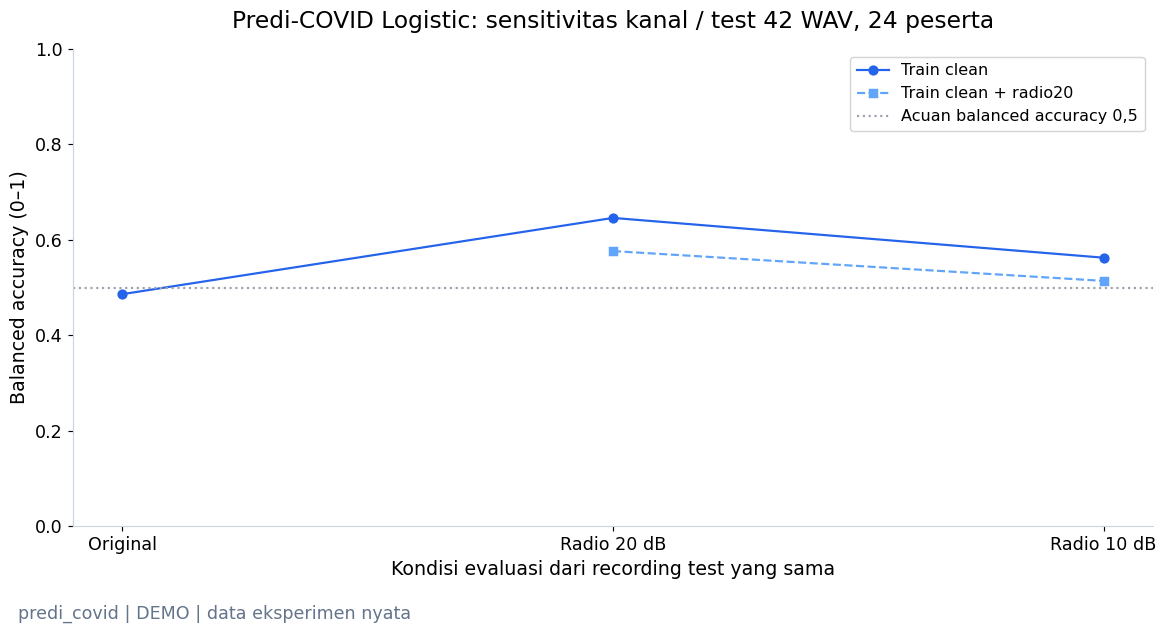

**Yang terlihat:** Model clean dan augmented dinilai pada turunan 20/10 dB dari recording test yang sama; 10 dB menambah noise relatif terhadap reference.

**Artinya:** Kurva menguji sensitivitas, bukan memilih kondisi dengan skor tertinggi; tidak ada tuning pada test.

**Perlu diingat:** SNR simulasi dihitung dari noise tambahan yang diketahui, bukan estimasi SNR asli suara klinis.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

In [41]:
if PREDI_AVAILABLE:
    fig,ax = plt.subplots(figsize=(11,5.5),layout='constrained')
    for regime,label,style,color in [('clean','Train clean','o-',COLORS['audio']),('aug20','Train clean + radio20','s--','#60A5FA')]:
        channels = ['clean','radio20','radio10'] if regime=='clean' else ['radio20','radio10']
        positions = [0 if channel=='clean' else 1 if channel=='radio20' else 2 for channel in channels]
        values = [radio_metrics['models'][regime+'_to_'+channel+'__logistic_c1']['test']['balanced_accuracy'] for channel in channels]
        ax.plot(positions,values,style,color=color,label=label)
    ax.axhline(.5,color=COLORS['baseline'],ls=':',label='Acuan balanced accuracy 0,5')
    ax.set(xticks=[0,1,2],xticklabels=['Original','Radio 20 dB','Radio 10 dB'],xlabel='Kondisi evaluasi dari recording test yang sama',
           ylabel='Balanced accuracy (0–1)',ylim=(0,1),title='Predi-COVID Logistic: sensitivitas kanal / test 42 WAV, 24 peserta')
    ax.legend(loc='upper right',fontsize=11)
    radio_book.show(fig,'radio_snr_sensitivity',
                    'Model clean dan augmented dinilai pada turunan 20/10 dB dari recording test yang sama; 10 dB menambah noise relatif terhadap reference.',
                    'Kurva menguji sensitivitas, bukan memilih kondisi dengan skor tertinggi; tidak ada tuning pada test.',
                    'SNR simulasi dihitung dari noise tambahan yang diketahui, bukan estimasi SNR asli suara klinis.')

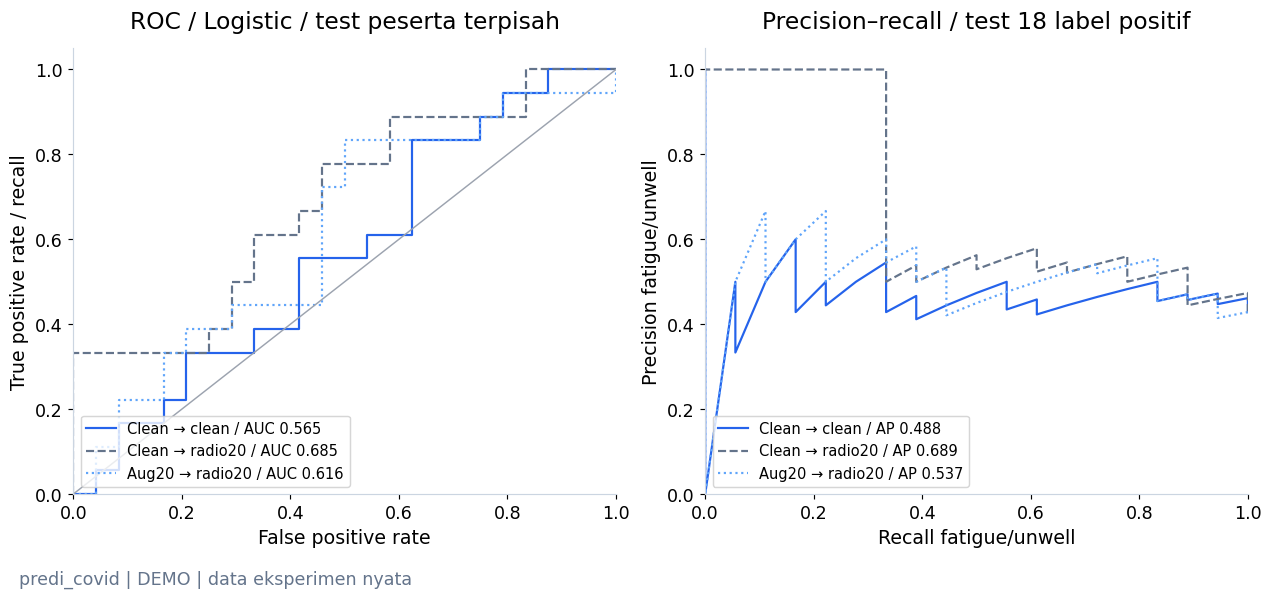

**Yang terlihat:** Kurva memakai skor kontinu Logistic pada label asli test; AUC dan AP dihitung dari prediksi tersimpan.

**Artinya:** Kurva menunjukkan trade-off threshold, sedangkan confusion matrix memakai threshold model tetap.

**Perlu diingat:** AP adalah average precision, bukan luas trapezoid PR; skor bukan tingkat fatigue atau probabilitas yang sudah dikalibrasi.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

In [42]:
if PREDI_AVAILABLE:
    from sklearn.metrics import roc_curve,precision_recall_curve
    fig,axes = plt.subplots(1,2,figsize=(12,5.2),layout='constrained')
    for regime,channel,label,color,style in [('clean','clean','Clean → clean',COLORS['audio'],'-'),
        ('clean','radio20','Clean → radio20',COLORS['secondary'],'--'),('aug20','radio20','Aug20 → radio20','#60A5FA',':')]:
        key = regime+'_to_'+channel+'__logistic_c1'
        rows = radio_predictions[radio_predictions.model.eq(key)&radio_predictions.split.eq('test')]
        fpr,tpr,_ = roc_curve(rows.truth,rows.score_1)
        precision,recall,_ = precision_recall_curve(rows.truth,rows.score_1)
        value = radio_metrics['models'][key]['test']
        axes[0].plot(fpr,tpr,color=color,ls=style,label=f"{label} / AUC {value['roc_auc']:.3f}")
        axes[1].plot(recall,precision,color=color,ls=style,label=f"{label} / AP {value['average_precision']:.3f}")
    for axis in axes:
        axis.set(xlim=(0,1),ylim=(0,1.05));axis.legend(loc='lower left',fontsize=10)
    axes[0].plot([0,1],[0,1],color=COLORS['baseline'],lw=1)
    axes[0].set(xlabel='False positive rate',ylabel='True positive rate / recall',title='ROC / Logistic / test peserta terpisah')
    axes[1].set(xlabel='Recall fatigue/unwell',ylabel='Precision fatigue/unwell',title='Precision–recall / test 18 label positif')
    radio_book.show(fig,'radio_roc_pr',
                    'Kurva memakai skor kontinu Logistic pada label asli test; AUC dan AP dihitung dari prediksi tersimpan.',
                    'Kurva menunjukkan trade-off threshold, sedangkan confusion matrix memakai threshold model tetap.',
                    'AP adalah average precision, bukan luas trapezoid PR; skor bukan tingkat fatigue atau probabilitas yang sudah dikalibrasi.')

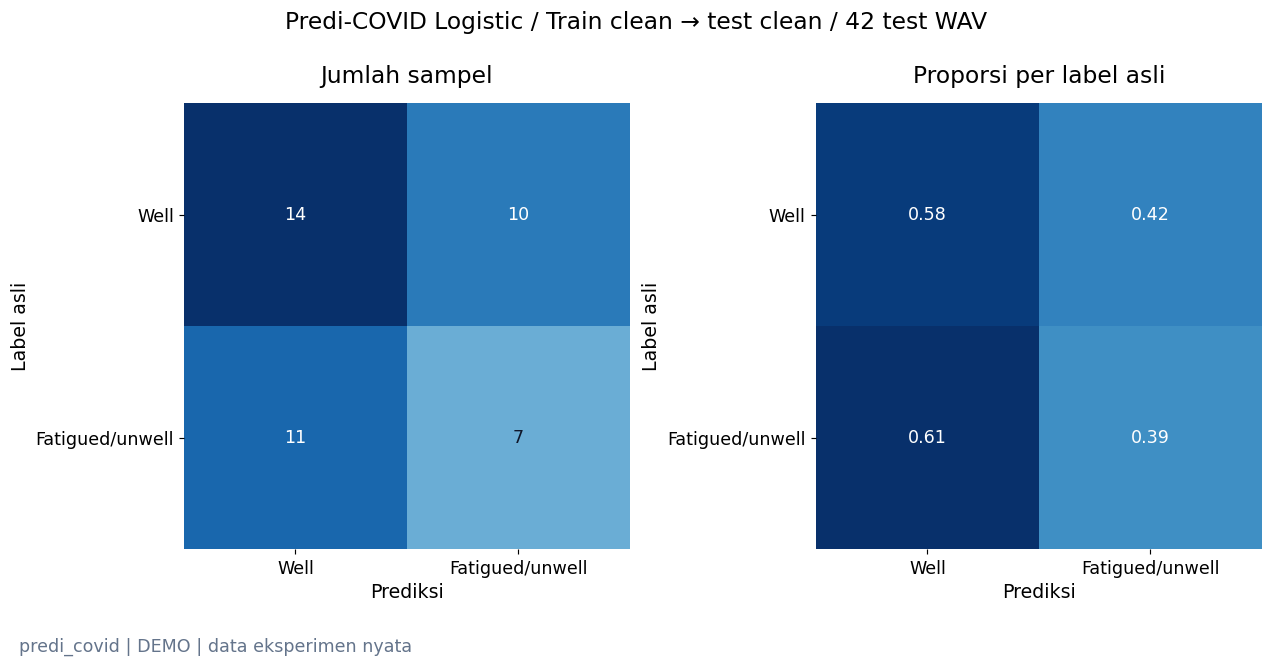

**Yang terlihat:** Recall fatigue/unwell 0.389; support positif 18 dan negatif 24 recording.

**Artinya:** Matriks menampilkan false negatives/false alarms pada populasi identik untuk tiga kondisi primer.

**Perlu diingat:** Label klinis mencampur fatigue dan unwell; hasil bukan diagnosis atau deteksi fatigue ATC.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

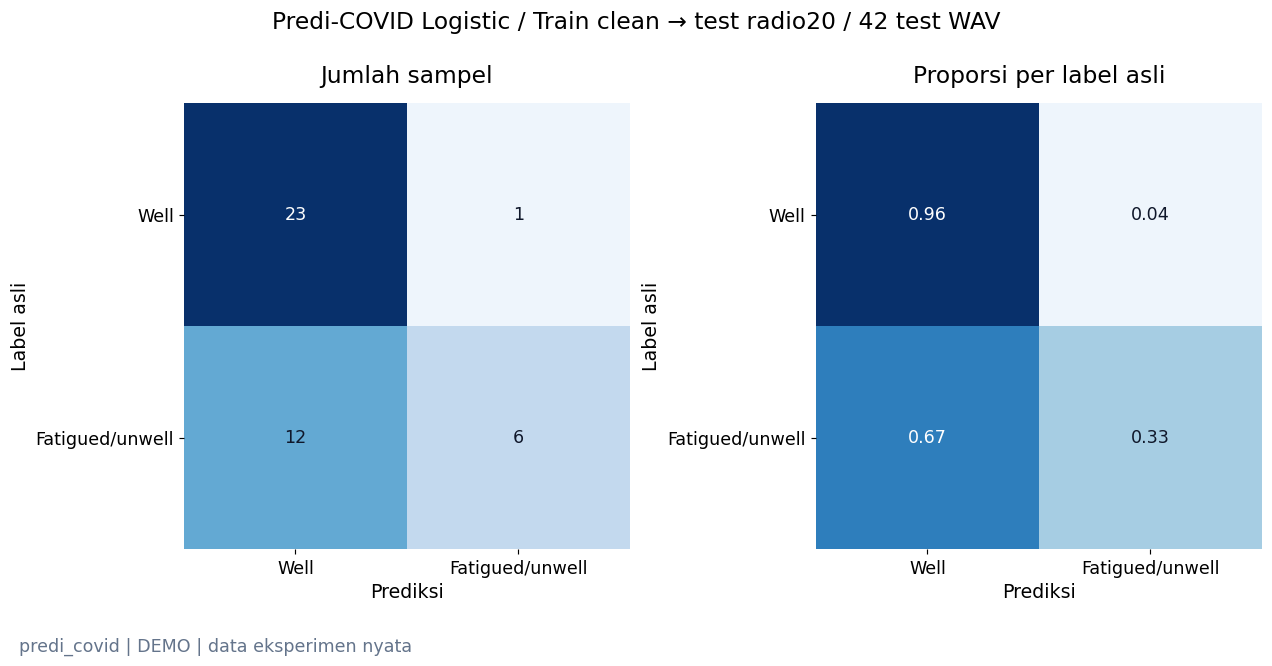

**Yang terlihat:** Recall fatigue/unwell 0.333; support positif 18 dan negatif 24 recording.

**Artinya:** Matriks menampilkan false negatives/false alarms pada populasi identik untuk tiga kondisi primer.

**Perlu diingat:** Label klinis mencampur fatigue dan unwell; hasil bukan diagnosis atau deteksi fatigue ATC.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

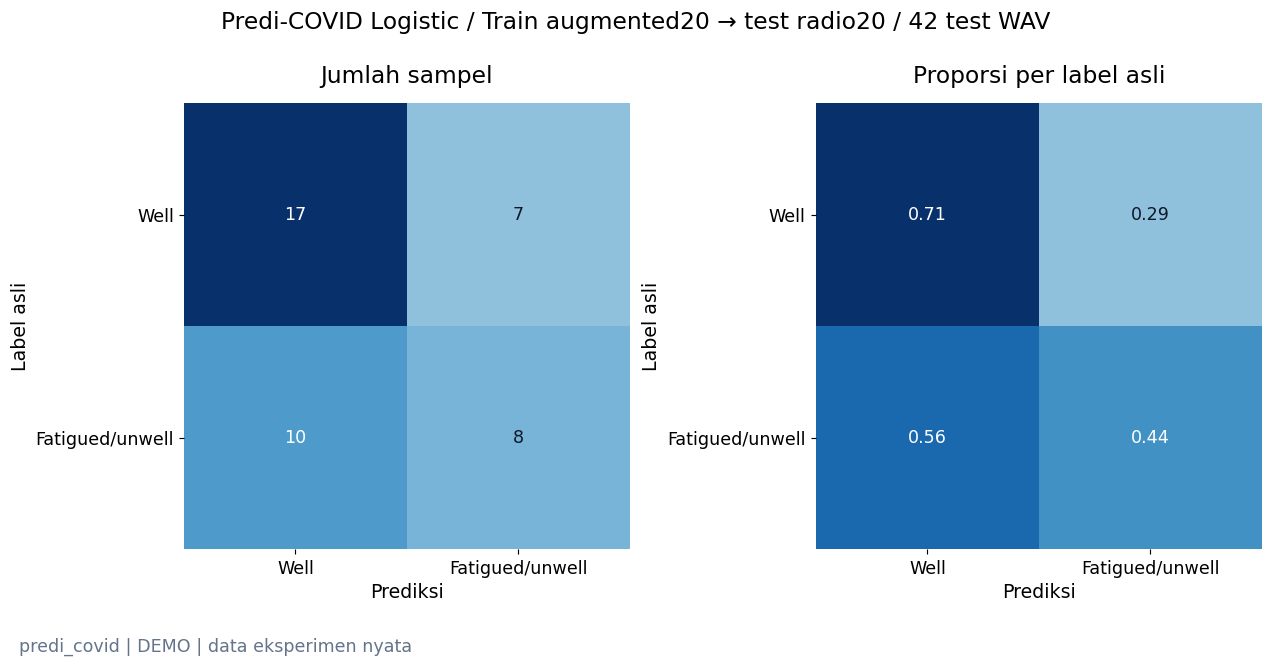

**Yang terlihat:** Recall fatigue/unwell 0.444; support positif 18 dan negatif 24 recording.

**Artinya:** Matriks menampilkan false negatives/false alarms pada populasi identik untuk tiga kondisi primer.

**Perlu diingat:** Label klinis mencampur fatigue dan unwell; hasil bukan diagnosis atau deteksi fatigue ATC.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

Model/condition,Kelas,precision,recall,f1-score,support
clean_to_clean__dummy_majority,0,0.571,1.000,0.727,24.0
clean_to_clean__dummy_majority,1,0.000,0.000,0.000,18.0
clean_to_clean__logistic_c1,0,0.560,0.583,0.571,24.0
clean_to_clean__logistic_c1,1,0.412,0.389,0.400,18.0
clean_to_clean__linear_svm_c1,0,0.593,0.667,0.627,24.0
clean_to_clean__linear_svm_c1,1,0.467,0.389,0.424,18.0
clean_to_radio20__dummy_majority,0,0.571,1.000,0.727,24.0
clean_to_radio20__dummy_majority,1,0.000,0.000,0.000,18.0
clean_to_radio20__logistic_c1,0,0.657,0.958,0.780,24.0
clean_to_radio20__logistic_c1,1,0.857,0.333,0.480,18.0


In [43]:
if PREDI_AVAILABLE:
    for regime,channel,title in [('clean','clean','Train clean → test clean'),('clean','radio20','Train clean → test radio20'),('aug20','radio20','Train augmented20 → test radio20')]:
        result = radio_metrics['models'][regime+'_to_'+channel+'__logistic_c1']['test']
        fig = confusion_pair(result,['Well','Fatigued/unwell'],'Predi-COVID Logistic / '+title+' / 42 test WAV')
        radio_book.show(fig,'radio_confusion_'+regime+'_'+channel,
                        f"Recall fatigue/unwell {result['classification_report']['1']['recall']:.3f}; support positif 18 dan negatif 24 recording.",
                        'Matriks menampilkan false negatives/false alarms pada populasi identik untuk tiga kondisi primer.',
                        'Label klinis mencampur fatigue dan unwell; hasil bukan diagnosis atau deteksi fatigue ATC.')
    class_rows = []
    for key,value in radio_metrics['models'].items():
        if value['evaluation_channel']=='radio10':continue
        for label in ['0','1']:
            class_rows.append({'Model/condition':key,'Kelas':label,**value['test']['classification_report'][label]})
    display(HTML('<details><summary>Precision / recall / F1 / support semua model primer</summary>'+pd.DataFrame(class_rows).round(3).to_html(index=False)+'</details>'))

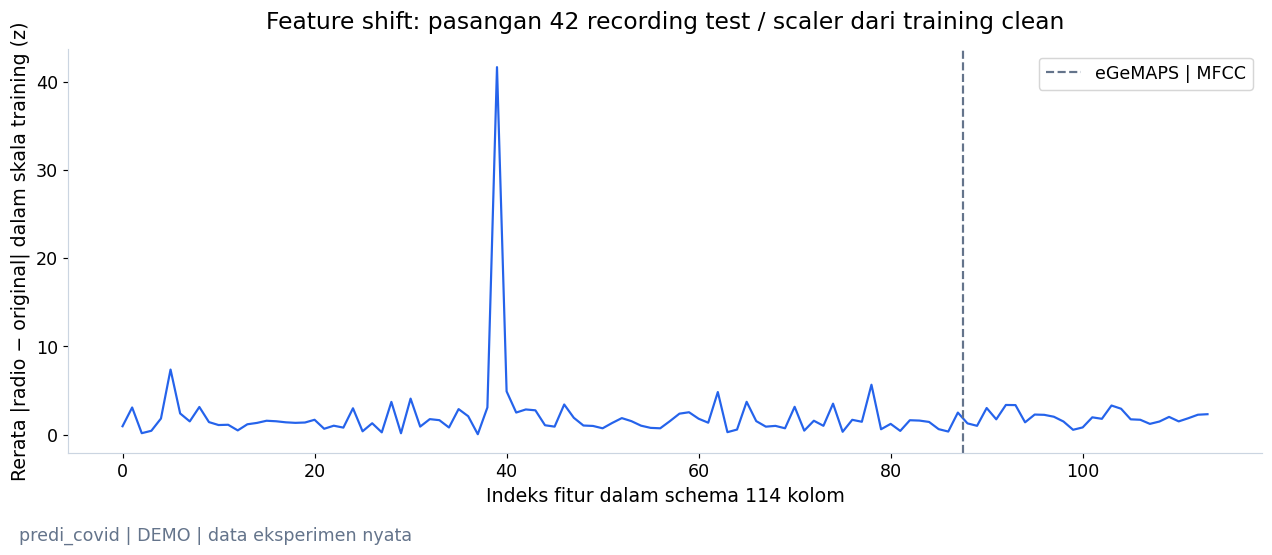

**Yang terlihat:** Setiap titik merangkum perubahan fitur pada pasangan recording yang sama; scaler tidak di-fit ulang pada test.

**Artinya:** Perubahan besar menunjukkan representasi sensitif terhadap kanal, bukan bahwa kondisi fatigue berubah.

**Perlu diingat:** Analisis ini deskriptif setelah evaluasi; tidak dipakai memilih fitur atau tuning parameter test.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

,Feature,Original,Radio20
0,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,23.9642,29.9331
10,egemaps__loudness_sma3_amean,0.5639,0.4218
20,egemaps__spectralFlux_sma3_amean,0.2917,0.1622
30,egemaps__jitterLocal_sma3nz_amean,0.0221,0.0547
41,egemaps__F1frequency_sma3nz_stddevNorm,0.4230,0.2819
51,egemaps__F2amplitudeLogRelF0_sma3nz_stddevNorm,-0.7186,-0.7280
61,egemaps__hammarbergIndexV_sma3nz_stddevNorm,0.2258,0.3407
71,egemaps__mfcc2V_sma3nz_stddevNorm,1.1890,-0.3053
82,egemaps__VoicedSegmentsPerSec,2.6424,3.2342
92,mfcc_04_mean,3.9456,-34.6473


In [44]:
if PREDI_AVAILABLE:
    clean_pipeline = radio_models['clean__logistic_c1']
    clean_test = predi_data[predi_data.split.eq('test')]
    radio_test = radio_tables['radio20'][radio_tables['radio20'].split.eq('test')]
    clean_matrix = clean_pipeline[:-1].transform(clean_test[audio_columns])
    radio_matrix = clean_pipeline[:-1].transform(radio_test[audio_columns])
    feature_shift = np.mean(np.abs(radio_matrix-clean_matrix),axis=0)
    fig,ax = plt.subplots(figsize=(12,4.8),layout='constrained')
    ax.plot(np.arange(len(audio_columns)),feature_shift,color=COLORS['audio'])
    ax.axvline(87.5,color=COLORS['secondary'],ls='--',label='eGeMAPS | MFCC')
    ax.set(xlabel='Indeks fitur dalam schema 114 kolom',ylabel='Rerata |radio − original| dalam skala training (z)',
           title='Feature shift: pasangan 42 recording test / scaler dari training clean')
    ax.legend(loc='upper right')
    radio_book.show(fig,'radio_feature_shift',
                    'Setiap titik merangkum perubahan fitur pada pasangan recording yang sama; scaler tidak di-fit ulang pada test.',
                    'Perubahan besar menunjukkan representasi sensitif terhadap kanal, bukan bahwa kondisi fatigue berubah.',
                    'Analisis ini deskriptif setelah evaluasi; tidak dipakai memilih fitur atau tuning parameter test.')
    example_id = clean_test.sort_values('sample_id').sample_id.iloc[0]
    comparison = pd.DataFrame({'Feature':audio_columns,
        'Original':clean_test.set_index('sample_id').loc[example_id,audio_columns].to_numpy(float),
        'Radio20':radio_test.set_index('sample_id').loc[example_id,audio_columns].to_numpy(float)})
    display(comparison.iloc[np.linspace(0,len(comparison)-1,12,dtype=int)].round(4))

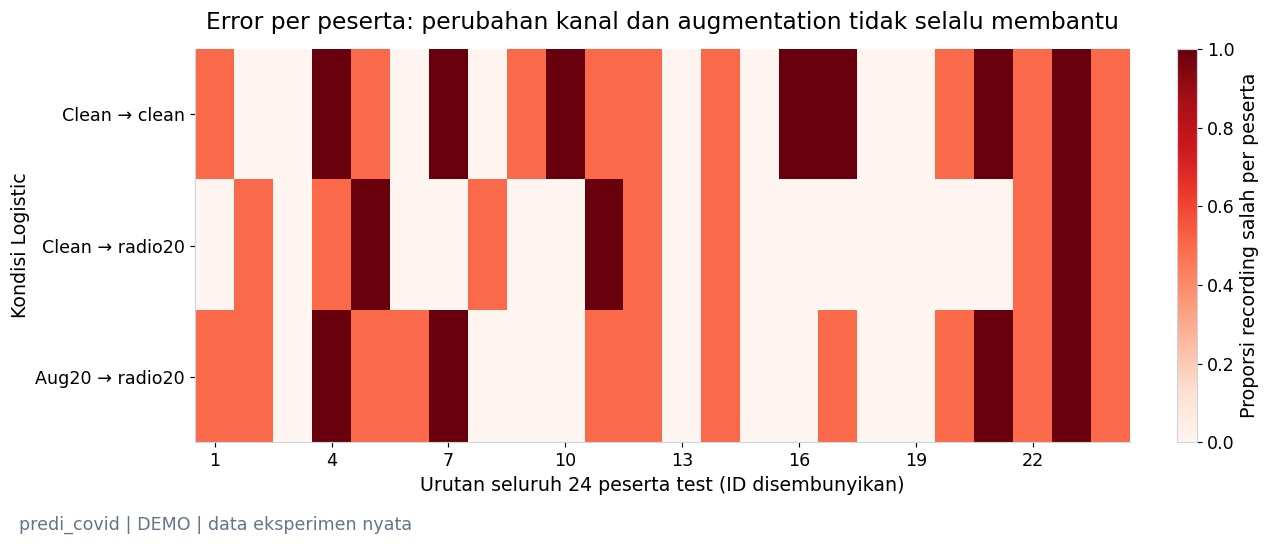

**Yang terlihat:** Semua peserta test ditampilkan pada urutan yang sama untuk ketiga kondisi; merah lebih pekat berarti lebih banyak prediksi salah.

**Artinya:** Perubahan pooled score dapat menyembunyikan peserta yang dirugikan; satu/dua recording per peserta membuat error individual kasar.

**Perlu diingat:** Tidak ada seleksi subjek terbaik atau CI yang menganggap klip berulang sebagai orang independen.

*Sumber: `20261023T105608840284Z_seed42_0d3b34` · REAL / CACHED; inference dihitung ulang.*

,Contoh,model,truth,prediction,score_1
114,contoh-21b227f7,clean_to_clean__logistic_c1,0,0,0.0445
115,contoh-43fd1b69,clean_to_clean__logistic_c1,0,1,0.5441
116,contoh-51f5e5b7,clean_to_clean__logistic_c1,0,0,0.0024
117,contoh-d8ee7851,clean_to_clean__logistic_c1,0,0,0.0039
118,contoh-48eb995c,clean_to_clean__logistic_c1,0,0,0.0017
119,contoh-e84e972c,clean_to_clean__logistic_c1,1,0,0.2439
348,contoh-21b227f7,clean_to_radio20__logistic_c1,0,0,0.0293
349,contoh-43fd1b69,clean_to_radio20__logistic_c1,0,0,0.0000
350,contoh-51f5e5b7,clean_to_radio20__logistic_c1,0,0,0.0000
351,contoh-d8ee7851,clean_to_radio20__logistic_c1,0,1,0.5063


In [45]:
if PREDI_AVAILABLE:
    selected_conditions = ['clean_to_clean__logistic_c1','clean_to_radio20__logistic_c1','aug20_to_radio20__logistic_c1']
    errors = radio_predictions[radio_predictions.model.isin(selected_conditions)&radio_predictions.split.eq('test')].copy()
    errors['error'] = errors.truth.ne(errors.prediction)
    subject_error = errors.groupby(['model','subject_id']).error.mean().unstack().reindex(selected_conditions)
    fig,ax = plt.subplots(figsize=(12,4.7),layout='constrained')
    image = ax.imshow(subject_error.to_numpy(),aspect='auto',cmap='Reds',vmin=0,vmax=1)
    ax.set(xlabel='Urutan seluruh 24 peserta test (ID disembunyikan)',ylabel='Kondisi Logistic',
           yticks=[0,1,2],yticklabels=['Clean → clean','Clean → radio20','Aug20 → radio20'],
           xticks=np.arange(0,len(subject_error.columns),3),xticklabels=np.arange(1,len(subject_error.columns)+1,3),
           title='Error per peserta: perubahan kanal dan augmentation tidak selalu membantu')
    fig.colorbar(image,ax=ax,label='Proporsi recording salah per peserta')
    radio_book.show(fig,'radio_subject_errors',
                    'Semua peserta test ditampilkan pada urutan yang sama untuk ketiga kondisi; merah lebih pekat berarti lebih banyak prediksi salah.',
                    'Perubahan pooled score dapat menyembunyikan peserta yang dirugikan; satu/dua recording per peserta membuat error individual kasar.',
                    'Tidak ada seleksi subjek terbaik atau CI yang menganggap klip berulang sebagai orang independen.')
    case_ids = sorted(clean_test.sample_id)[:6]
    case_table = radio_predictions[radio_predictions.sample_id.isin(case_ids)&radio_predictions.model.isin(selected_conditions)&radio_predictions.split.eq('test')].copy()
    from atc_fatigue.research.data import pseudonym
    case_table['Contoh'] = case_table.sample_id.map(pseudonym)
    display(case_table[['Contoh','model','truth','prediction','score_1']].round(4))

In [46]:
if PREDI_AVAILABLE:
    radio_book.finish()
    if RUN_MODE == 'FULL':
        radio_run.complete(radio_metrics,{'evaluation_rows':len(predi_data),'source_rows':len(predi_manifest),
           'derived_versions':len(radio_tables),'independent_test_recordings':predi_sizes['test'],'test_subjects':24,
           'subject_overlap':0,'no_test_training_augmentation':True,'checkpoints':len(radio_models),
           'snr_max_error_db':float(abs(radio_quality.measured_snr_db-radio_quality.requested_snr_db).max())},warning_records)
    clean_score = radio_metrics['models']['clean_to_clean__logistic_c1']['test']['macro_f1']
    radio_score = radio_metrics['models']['clean_to_radio20__logistic_c1']['test']['macro_f1']
    augmented_score = radio_metrics['models']['aug20_to_radio20__logistic_c1']['test']['macro_f1']
    display(Markdown(f'**Hasil channel study:** Logistic Macro F1 clean→clean **{clean_score:.4f}**, clean→radio20 **{radio_score:.4f}**, aug20→radio20 **{augmented_score:.4f}**. '
        'Nilai ini harus dibaca bersama balanced accuracy, recall, dukungan test dan error per peserta. Augmentation tidak diasumsikan meningkatkan hasil. '
        '**Yang diuji adalah robustness terhadap kanal buatan pada populasi klinis, bukan transfer fatigue ke operator ATC.**'))
    difference = augmented_score-radio_score
    fatigue_recall = radio_metrics['models']['clean_to_radio20__logistic_c1']['test']['classification_report']['1']['recall']
    display(Markdown(f'**Yang terlihat:** augmentation mengubah Macro F1 pada radio20 sebesar {difference:+.4f}; recall fatigue/unwell model clean→radio20 hanya {fatigue_recall:.3f}. '
        '**Artinya:** filter/noise tidak selalu menurunkan pooled score, dan tambahan data turunan tidak otomatis memperbaiki generalisasi. '
        '**Perlu diingat:** test berisi24 peserta dengan label klinis terbatas; penyebab perubahan tidak dapat dipastikan tanpa validasi eksternal dan kontrol confound. Tidak ada pemilihan kanal karena skornya lebih tinggi.'))


**Hasil channel study:** Logistic Macro F1 clean→clean **0.4857**, clean→radio20 **0.6298**, aug20→radio20 **0.5758**. Nilai ini harus dibaca bersama balanced accuracy, recall, dukungan test dan error per peserta. Augmentation tidak diasumsikan meningkatkan hasil. **Yang diuji adalah robustness terhadap kanal buatan pada populasi klinis, bukan transfer fatigue ke operator ATC.**

**Yang terlihat:** augmentation mengubah Macro F1 pada radio20 sebesar -0.0541; recall fatigue/unwell model clean→radio20 hanya 0.333. **Artinya:** filter/noise tidak selalu menurunkan pooled score, dan tambahan data turunan tidak otomatis memperbaiki generalisasi. **Perlu diingat:** test berisi24 peserta dengan label klinis terbatas; penyebab perubahan tidak dapat dipastikan tanpa validasi eksternal dan kontrol confound. Tidak ada pemilihan kanal karena skornya lebih tinggi.

### Kesimpulan Track 1

Data asli, parameter transformasi, 114 input numerik, train-only preprocessing, fit model, prediksi dan label dapat ditelusuri.
Dua player Predi-COVID dan galeri turunan berlisensi kini tersedia publik. Media sumber dengan pembatasan redistribusi tetap lokal; semua skor dan target tetap seperti eksperimen sebelumnya.
Predi-COVID tetap weak clinical fatigue/unwell, ATCOSIM tetap domain audio tanpa fatigue labels.
Sebelum studi ATC diperlukan protokol ground truth, variasi operator/perangkat, kondisi radio terukur dan test eksternal independen.

In [47]:
warning_context.__exit__(None,None,None)

**Kesimpulan:** data suara ATC asli berhasil masuk ke tabel fitur, tetapi tidak menghasilkan skor fatigue. Untuk mengulang seluruh subset, jalankan `ATC_NOTEBOOK_MODE=FULL .venv/bin/python scripts/10_execute_notebook_v3.py --mode FULL --notebook 01_audio_analysis.ipynb`. Mode DEMO adalah pilihan presentasi; petunjuk lengkap ada di [README v3](README.md).

Predi-COVID menambah supervised benchmark label fatigue/unwell klinis, dengan batas domain dan label yang dijelaskan di Bagian 7. Tidak ada estimasi performa fatigue ATC.